# Pneumonia detection: corrected, config-driven pipeline

**How to use:** edit the options in the **CONFIG cell** (the first code cell after the imports), then *Run All*. Every distinct config gets its own folder under `runs/` (checkpoint + `results.json`), and the **last cell** compares all runs side by side. Training is skipped automatically if that config already has a checkpoint.

**Suggested sequence of runs** (change the config, Run All, compare in the last cell):
1. **Default**: both sources, resize-first CLAHE, artifact-matched Guangzhou.
2. `TRAIN_SOURCES = ["nih"]`: does Guangzhou help NIH at all?
3. `TRAIN_SOURCES = ["guangzhou"]`: true external test, read the **nih** line.
4. `USE_CLAHE = False`: does CLAHE help or hurt?
5. `INTENSITY_NORM = "equalize"`: does removing global brightness cues lower source separability without hurting NIH?
6. Learning curve (is the model data-limited?): `TRAIN_SOURCES = ["nih"]` with `TRAIN_FRACTION` = 0.25, 0.5 and 1.0. If NIH AUROC is still rising clearly (more than ~0.03) from 50% to 100%, more data will help; if it is flat within noise, the limit is label quality or the model, not the number of images.
7. To compare with the original run: `MATCH_GZ_ASPECT = MATCH_GZ_BORDER = False` and `CLAHE_FIRST = True`.

**What was fixed relative to the original notebook**
1. Evaluation bug: a single-logit head was decoded with `argmax` (always 0). Now `sigmoid(logit) >= threshold`.
2. NIH was silently empty. NIH now comes from a small streamed subset (`prepare_nih_subset.py`) and the loader fails loudly if it is missing.
3. Validation used training augmentation. Now separate train and eval transforms.
4. Image-level random split. Now patient-level, class-stratified, and done separately per source, so each source's test images are identical in every run (runs are comparable; the comparison table shows a test-set id).
5. Source confound: both classes in each source, metrics reported per source, plus external-validation runs.
6. Operating point: each source gets its own decision threshold, picked on its own validation images (`THRESHOLD_MODE`), because a pooled threshold follows the easy source. A duplicate-image audit and a seed-noise table are at the end.
6b. Imbalance and objective: `pos_weight`; the best epoch is picked by the mean of the per-source validation AUROCs (`SELECT_ON`), so the easy source cannot dominate; threshold chosen on validation.
7. Preprocessing shortcuts: probes show Guangzhou's label is predictable from image shape and framing. Opt-in artifact matching, resize-first CLAHE, and a CLAHE ablation switch.
8. Source leakage controls (CONFIG cell): per-source class balance (`BALANCE_SOURCE_PRIORS`), artifact matching, resize-first CLAHE, and optional final histogram equalisation (`INTENSITY_NORM`). The data cell prints the source-only baseline AUROC; the probe cell shows how well simple statistics still separate sources and labels.
9. No hard-coded credentials.


In [ ]:
# ---- COLAB SETUP (skip this cell in VS Code) ----
import os, subprocess
from pathlib import Path
from google.colab import drive, userdata
drive.mount("/content/drive")
PROJECT = Path("/content/drive/MyDrive/pneumonia")      # holds prepare_nih_subset.py, nih_subset/ and runs/ (survives disconnects)
os.chdir(PROJECT)                                       # the notebook uses relative paths: runs/, nih_subset/, prepare_nih_subset.py
os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")
LOCAL = Path("/content/chest_xray_data")                # Guangzhou goes on the fast local disk, re-downloaded each session
if not (LOCAL / "chest_xray" / "train").exists():
    subprocess.run(["kaggle", "datasets", "download", "-d", "paultimothymooney/chest-xray-pneumonia",
                    "--unzip", "-p", str(LOCAL)], check=True)

In [1]:
# Installs anything missing into THIS notebook's kernel environment, then asks for a restart.
import importlib.util
from IPython import get_ipython
needed = {"numpy": "numpy", "pandas": "pandas", "cv2": "opencv-python", "torch": "torch", "torchvision": "torchvision",
          "sklearn": "scikit-learn", "datasets": "datasets", "PIL": "pillow", "matplotlib": "matplotlib"}
missing = [pip for mod, pip in needed.items() if importlib.util.find_spec(mod) is None]
if missing:
    get_ipython().run_line_magic("pip", "install " + " ".join(missing))
    print("Installed:", missing, "-> now RESTART the kernel (Restart button in the toolbar) and run from the top.")
else:
    print("All packages present.")

All packages present.


In [2]:
import os, re, sys, json, random, warnings
from pathlib import Path
import numpy as np, pandas as pd, cv2, torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix, classification_report
from IPython import get_ipython

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)  # cpu works locally but is slow: use DEBUG_FRAC and fewer epochs, or a GPU

device: cpu


In [3]:
# =============================== EXPERIMENT CONFIG ===============================
# Everything you might want to change lives here. Run All afterwards. Each distinct config gets its own folder under runs/
# (checkpoint + results.json); the last cell of the notebook compares all runs.
TRAIN_SOURCES   = ["guangzhou", "nih"]  # ["nih"] = does Guangzhou help NIH at all? | ["guangzhou"] = true external test on NIH.
                                        # The test set always keeps both sources; val follows TRAIN_SOURCES so thresholds never see held-out data.
CLAHE_FIRST     = False   # False = resize to 224, then CLAHE (same scale for both sources; recommended).  True = CLAHE at original size, then resize (first run).
USE_CLAHE       = True    # False = resize only: the "does CLAHE help or hurt?" ablation.
MATCH_GZ_ASPECT = True    # Guangzhou only: balance classes within aspect-ratio bins (image shape alone predicted the label, AUROC ~0.92).
MATCH_GZ_BORDER = True    # Guangzhou only: also balance within bins of black-border share. Together these discard much of Guangzhou (kept count is printed in the data cell).
BALANCE_SOURCE_PRIORS = True   # Subsample every source to 50/50 classes, so "which dataset is this image from?" says nothing about the label.
                               # (Guangzhou is 73% pneumonia, NIH 50%: the source-only baseline AUROC was 0.618.) A no-op when MATCH_GZ_* is on.
INTENSITY_NORM  = "none"  # "equalize" = histogram-equalise every image as the LAST step, so global brightness/contrast statistics are identical for
                          # every image (hits the biggest measured source cue, image stats 0.94-0.96) but also removes real "haze" signal.
                          # Treat it as an ablation: keep it only if NIH AUROC does not fall.
EPOCHS          = 4       # val AUROC plateaued at epoch 3-4 in the first run; later epochs only overfit.
SELECT_ON       = "mean_source"   # which validation metric picks the best epoch. "pooled" = old behaviour: the easy source (Guangzhou) can dominate it.
                                  # "mean_source" = average of the per-source AUROCs. "nih" = the clean source only.
SEED            = 42      # also drives the train/val/test split, so another seed = another split. Use the SAME seed when comparing configs; vary it to measure run-to-run noise.
THRESHOLD_MODE  = "per_source"   # "per_source": each source gets its own threshold, picked on that source's validation images (a shared threshold follows the easy
                                 # source: NIH sensitivity was 0.50 at the pooled threshold). "shared": one pooled threshold. AUROC is unaffected either way.
RETRAIN         = True   # False = if this config already has a checkpoint, load it instead of training again.
TRAIN_FRACTION  = 1.0     # learning-curve runs: use only this fraction of the TRAINING images (val/test untouched). Is the model data-limited? See the notes at the end.
DEBUG_FRAC      = 1.0     # e.g. 0.1 = quick smoke test on 10% of the images (its run name gets a "debug" suffix).
RUN_NAME        = None    # None = built from the settings above; or give your own.

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

def _auto_run_name():
    parts = ["-".join(TRAIN_SOURCES), ("clahefirst" if CLAHE_FIRST else "resizefirst") if USE_CLAHE else "noclahe"]
    if MATCH_GZ_ASPECT or MATCH_GZ_BORDER:
        parts.append("match" + ("A" if MATCH_GZ_ASPECT else "") + ("B" if MATCH_GZ_BORDER else ""))
    if BALANCE_SOURCE_PRIORS and not (MATCH_GZ_ASPECT or MATCH_GZ_BORDER): parts.append("bal")   # matching already balances classes
    if INTENSITY_NORM != "none": parts.append("eq")
    if TRAIN_FRACTION < 1.0: parts.append(f"frac{TRAIN_FRACTION}")
    if SEED != 42: parts.append(f"seed{SEED}")
    parts.append("s2")   # split version 2 (per-source split). Checkpoints trained under the old joint split must NOT be reused: their test images may have been seen in training.
    if DEBUG_FRAC < 1.0: parts.append(f"debug{DEBUG_FRAC}")
    return "_".join(parts)
RUN_NAME = RUN_NAME or _auto_run_name()
RUN_DIR, CKPT = Path("runs") / RUN_NAME, Path("runs") / RUN_NAME / "best.pt"
print("run:", RUN_NAME, "->", RUN_DIR)

run: guangzhou-nih_resizefirst_matchAB_s2 -> runs\guangzhou-nih_resizefirst_matchAB_s2


In [ ]:
# ---- PATHS --------------------------------------------------------------------
# Guangzhou: already downloaded.  NIH: small balanced subset streamed from Hugging Face.
GZ_ROOT  = Path("/content/chest_xray_data/chest_xray")   # must contain train/ val/ test/
NIH_DIR  = Path("nih_subset")
NIH_META = NIH_DIR / "metadata.csv"

assert (GZ_ROOT / "train" / "NORMAL").exists(), f"Guangzhou folder not found or wrong level: {GZ_ROOT}"

if not NIH_META.exists():
    # streams ~2.5 GB from Hugging Face, keeps ~2000 images (tens of MB). Needs: pip install datasets pillow
    get_ipython().system(f'"{sys.executable}" prepare_nih_subset.py --per-class 1000 --out nih_subset')
print("Guangzhou found:", GZ_ROOT.exists(), "| NIH subset found:", NIH_META.exists())

Guangzhou found: True | NIH subset found: True


In [5]:
# ---- BUILD ONE DATAFRAME: path, label, source, patient ------------------------
def gz_patient(name):
    m = re.search(r"person(\d+)", name)
    if m: return "gzP_" + m.group(1)
    m = re.search(r"IM-(\d{4})", name)          # NORMAL files: IM-0115-0001.jpeg, NORMAL2-IM-0373-0001-0001.jpeg
    return "gzN_" + (m.group(1) if m else Path(name).stem)

rows = []
for split in ["train", "val", "test"]:
    for cat, lab in [("NORMAL", 0), ("PNEUMONIA", 1)]:
        for p in (GZ_ROOT / split / cat).glob("*.jpeg"):
            rows.append(dict(path=str(p), label=lab, source="guangzhou", patient=gz_patient(p.name)))
df_gz = pd.DataFrame(rows)
print("Guangzhou images found:", len(df_gz), "(the full dataset has 5856)")
assert len(df_gz) > 0, "no Guangzhou images found, check GZ_ROOT"

# ---- ARTIFACT MATCHING (opt-in) -------------------------------------------------
# Probes showed that in Guangzhou the image SHAPE alone predicts the label (AUROC ~0.92: pneumonia files are wider) and that
# seven global pixel statistics reach ~0.90 on raw images, partly through black framing borders. These flags keep, inside each
# bin of the chosen artifact, only as many images per class as the rarer class has, so the artifact carries no label information.
# Price: far fewer Guangzhou images. It does NOT touch other cues, so re-run cell 10 afterwards and read the Guangzhou numbers.
# (the switches MATCH_GZ_ASPECT / MATCH_GZ_BORDER live in the CONFIG cell)
if MATCH_GZ_ASPECT or MATCH_GZ_BORDER:
    from PIL import Image
    def _border_dark(p):
        g = cv2.imread(p, cv2.IMREAD_REDUCED_GRAYSCALE_4)                  # quarter-size decode: fast
        g = cv2.resize(g, (224, 224), interpolation=cv2.INTER_AREA)
        ring = np.ones(g.shape, bool); ring[24:-24, 24:-24] = False
        return float((g[ring] < 10).mean())
    keys = []
    if MATCH_GZ_ASPECT:
        asp = pd.Series([w / h for w, h in (Image.open(p).size for p in df_gz.path)], index=df_gz.index)
        df_gz["k_aspect"] = pd.qcut(asp.rank(method="first"), 10 if MATCH_GZ_BORDER else 20, labels=False); keys.append("k_aspect")
    if MATCH_GZ_BORDER:
        bd = pd.Series([_border_dark(p) for p in df_gz.path], index=df_gz.index)
        df_gz["k_border"] = pd.qcut(bd.rank(method="first"), 4, labels=False); keys.append("k_border")
    keep = []
    for _, bin_ in df_gz.groupby(keys):
        if bin_.label.nunique() < 2: continue
        k = bin_.label.value_counts().min()
        keep += [g.sample(k, random_state=SEED) for _, g in bin_.groupby("label")]
    n_before = len(df_gz)
    df_gz = pd.concat(keep).drop(columns=keys).reset_index(drop=True)
    print(f"artifact-matched Guangzhou: kept {len(df_gz)} of {n_before} images, pneumonia fraction {df_gz.label.mean():.2f}")
    if len(df_gz) < 400:
        print("!!! WARNING: very few Guangzhou images left. Turn one MATCH_ flag off, or train on NIH only. !!!")

# NIH subset written by prepare_nih_subset.py (label 1 = Pneumonia, 0 = No Finding only)
if NIH_META.exists():
    nih = pd.read_csv(NIH_META)
    nih["path"] = nih["path"].apply(lambda p: str(NIH_DIR / p))
    nih["patient"] = "nih_" + nih["patient_id"].astype(str)
    nih["source"] = "nih"
else:
    print("!!! NIH subset missing:", NIH_META)
    nih = pd.DataFrame(columns=["label", "path", "patient", "source"])
n_pos, n_neg = (nih.label == 1).sum(), (nih.label == 0).sum()
print(f"NIH images on disk: pneumonia={n_pos}, no-finding={n_neg}")
if min(n_pos, n_neg) < 50:
    print("!!! WARNING: NIH has (almost) no usable images on disk. Training on Guangzhou ONLY. !!!")
    df_nih = nih.iloc[0:0]
else:
    k = min(n_pos, n_neg, 1500)   # balanced classes *within* NIH so source != label
    df_nih = pd.concat([nih[nih.label == c].sample(k, random_state=SEED) for c in (0, 1)])

df = pd.concat([df_gz, df_nih[["path","label","source","patient"]]], ignore_index=True)
if BALANCE_SOURCE_PRIORS:                      # same number of pneumonia and normal images inside EVERY source
    n_all = len(df)
    k_by_source = df.groupby("source").label.apply(lambda s: int(s.value_counts().min()))
    df = pd.concat([g.groupby("label", group_keys=False).sample(n=k_by_source[s_], random_state=SEED)
                    for s_, g in df.groupby("source")], ignore_index=True)
    print(f"source priors balanced: {n_all} -> {len(df)} images")
df["strata"] = df.source + "_" + df.label.astype(str)
print(pd.crosstab(df.source, df.label))   # LOOK AT THIS. Each source should have both classes.
_prior = df.groupby("source").label.transform("mean")
print("source-only baseline AUROC on the whole dataset:", round(roc_auc_score(df.label, _prior), 3), "(0.5 = knowing the source tells you nothing about the label)")

if DEBUG_FRAC < 1.0:
    df = df.groupby("strata", group_keys=False).sample(frac=DEBUG_FRAC, random_state=SEED).reset_index(drop=True)
    print("DEBUG subset:", len(df), "images")

Guangzhou images found: 5855 (the full dataset has 5856)
artifact-matched Guangzhou: kept 1982 of 5855 images, pneumonia fraction 0.50
NIH images on disk: pneumonia=1000, no-finding=1000
source priors balanced: 3982 -> 3982 images
label         0     1
source               
guangzhou   991   991
nih        1000  1000
source-only baseline AUROC on the whole dataset: 0.5 (0.5 = knowing the source tells you nothing about the label)


In [6]:
# ---- PATIENT-LEVEL SPLIT, DONE SEPARATELY FOR EACH SOURCE (~71/14/14) ---------------
# Each source is split on its own, so a source's train/val/test images are IDENTICAL in every run, whatever happens to the OTHER source
# (artifact matching, balancing, ...). Splitting everything together made the NIH test set change whenever Guangzhou changed (in a
# simulation only ~22% of NIH test images were shared between configs), which would make cross-run NIH comparisons unreliable.
def group_split(d, n_splits):
    sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=SEED)
    a, b = next(sgkf.split(d, d.label, d.patient))             # stratify by class within the source
    return d.iloc[a].reset_index(drop=True), d.iloc[b].reset_index(drop=True)

def split_per_source(d, n_splits):
    keep, held = [], []
    for _, g in d.groupby("source"):
        g = g.sort_values("path").reset_index(drop=True)        # row order must not matter
        k, h = group_split(g, n_splits); keep.append(k); held.append(h)
    return pd.concat(keep, ignore_index=True), pd.concat(held, ignore_index=True)

trainval, test = split_per_source(df, 7)
train, val     = split_per_source(trainval, 6)
for a, b in [(train, val), (train, test), (val, test)]:
    assert not set(a.patient) & set(b.patient), "patient leakage between splits"
train = train[train.source.isin(TRAIN_SOURCES)].reset_index(drop=True)   # test keeps ALL sources
val   = val[val.source.isin(TRAIN_SOURCES)].reset_index(drop=True)       # val too, so the threshold never sees the held-out source
if TRAIN_FRACTION < 1.0:    # learning curve: fewer training images, identical val/test
    train = train.groupby(["source", "label"], group_keys=False).sample(frac=TRAIN_FRACTION, random_state=SEED).reset_index(drop=True)
assert len(train) > 0 and len(val) > 0, "empty train/val: check TRAIN_SOURCES and the data cell output"
for n, d in [("train", train), ("val", val), ("test", test)]:
    print(n, len(d), "| pneumonia rate:", round(d.label.mean(), 3), "|", d.source.value_counts().to_dict())

train 2865 | pneumonia rate: 0.505 | {'nih': 1448, 'guangzhou': 1417}
val 562 | pneumonia rate: 0.509 | {'guangzhou': 296, 'nih': 266}
test 555 | pneumonia rate: 0.463 | {'nih': 286, 'guangzhou': 269}


In [ ]:
# ---- DATASET / LOADERS --------------------------------------------------------
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
train_tf = transforms.Compose([transforms.ToPILImage(),
                               transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
                               transforms.RandomRotation(10),
                               transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
eval_tf  = transforms.Compose([transforms.ToPILImage(), transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

# (CLAHE_FIRST / USE_CLAHE are set in the CONFIG cell)
def load_and_preprocess(path):
    """grayscale -> CLAHE and resize to 224x224 (order set by CLAHE_FIRST; CLAHE skipped if USE_CLAHE is False; optional final histogram equalisation, INTENSITY_NORM) -> 3 identical channels (uint8 HxWx3). The ONE place preprocessing lives."""
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if img is None: raise FileNotFoundError(path)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    if not USE_CLAHE:
        img = cv2.resize(img, (224, 224), interpolation=cv2.INTER_AREA)
    elif CLAHE_FIRST:
        img = cv2.resize(clahe.apply(img), (224, 224), interpolation=cv2.INTER_AREA)
    else:
        img = clahe.apply(cv2.resize(img, (224, 224), interpolation=cv2.INTER_AREA))
    if INTENSITY_NORM == "equalize":
        img = cv2.equalizeHist(img)          # identical global histogram for every image
    return np.stack([img] * 3, axis=-1)

class XRayDS(Dataset):
    def __init__(self, d, tf):
        self.paths, self.labels, self.tf = d.path.tolist(), d.label.astype("float32").tolist(), tf
    def __len__(self): return len(self.paths)
    def __getitem__(self, i):
        return self.tf(load_and_preprocess(self.paths[i])), torch.tensor(self.labels[i])

NUM_WORKERS = 0 if os.name == "nt" else 2   # notebook-defined Datasets cannot be pickled by Windows worker processes
kw = dict(batch_size=32, num_workers=NUM_WORKERS, pin_memory=(device.type == "cuda"))
train_loader = DataLoader(XRayDS(train, train_tf), shuffle=True,  **kw)
val_loader   = DataLoader(XRayDS(val,   eval_tf),  shuffle=False, **kw)   # NO augmentation
test_loader  = DataLoader(XRayDS(test,  eval_tf),  shuffle=False, **kw)

## Preprocessing checks (run before training)
Every image goes through `load_and_preprocess`: grayscale, then CLAHE (local contrast) and resize to 224x224 in the order set by `CLAHE_FIRST` (CLAHE is skipped when `USE_CLAHE = False`), then copy to 3 channels. After that `eval_tf` (tensor in [0,1], ImageNet mean/std) or `train_tf` (random crop and rotation first). The cells below test that exact code: a picture grid to eyeball, numeric sanity checks, and a test of whether simple image statistics can separate sources or labels.

**Reading the probe cell.** "image stats" and "border-only" are things the network can see; "aspect ratio only" is the squash artifact; "raw size / file size" is invisible to the network (it only sees 224 px) and is just a rough diagnostic of dataset differences. After artifact matching, Guangzhou's *aspect* and *border-only* probes should fall towards 0.5 to 0.6. NIH should already sit near 0.5.


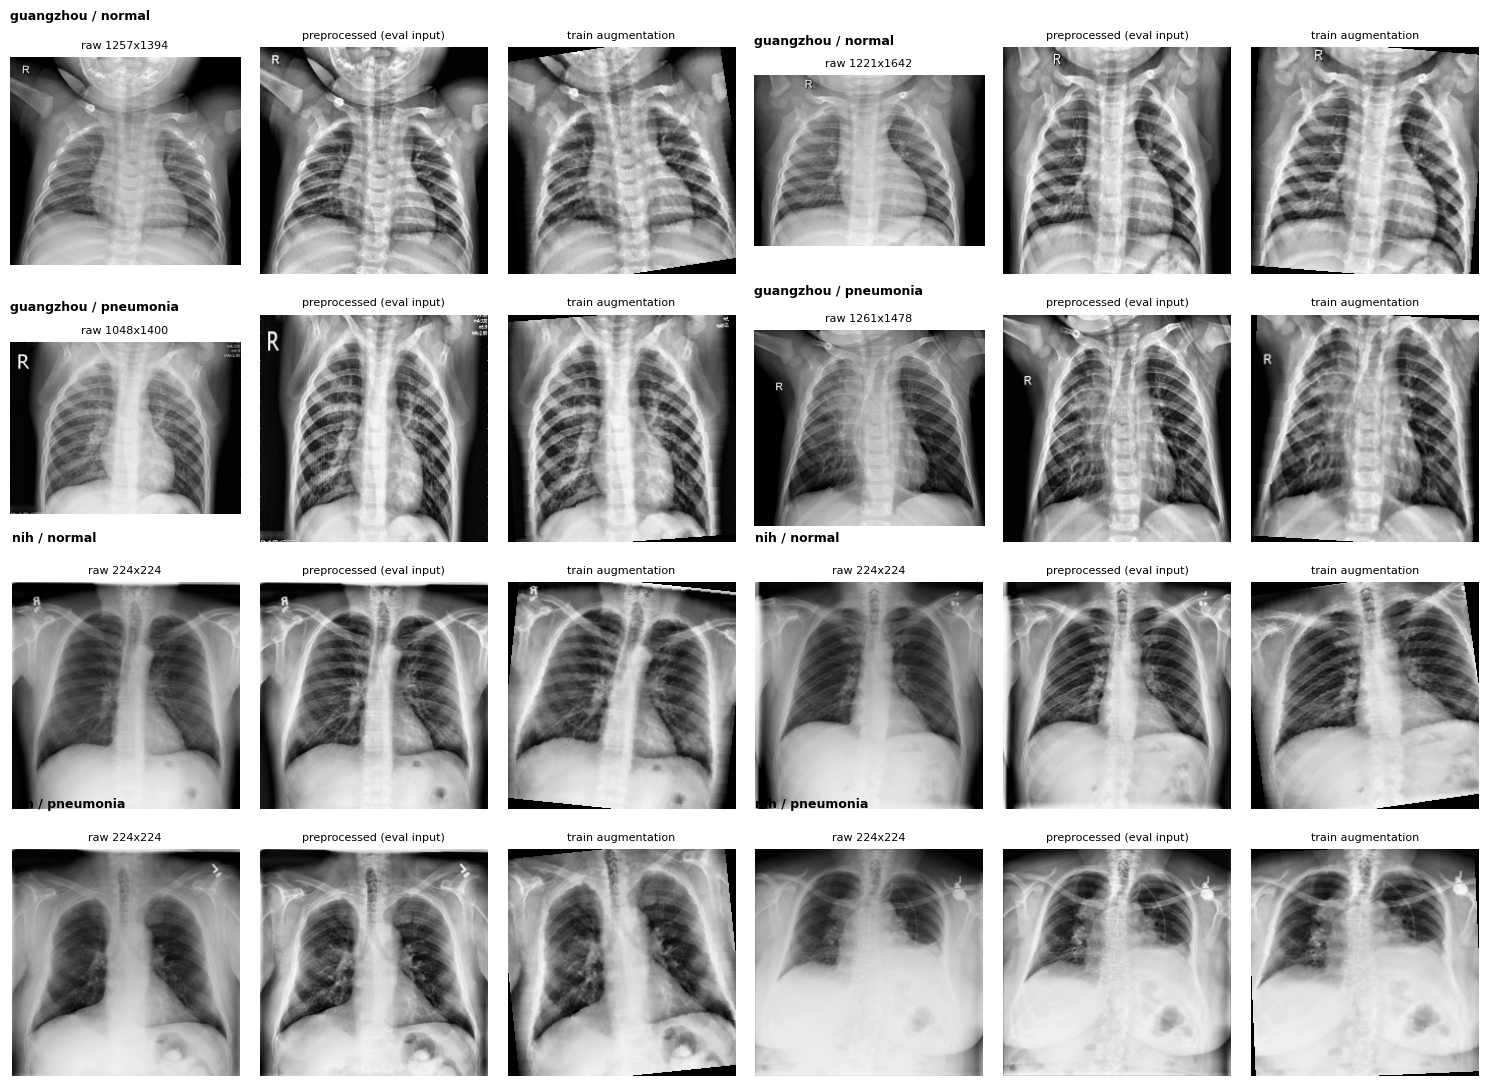

In [8]:
# ---- LOOK AT IT: raw vs preprocessed vs augmented, one row per source x class ------
import matplotlib.pyplot as plt
MEAN_T, STD_T = torch.tensor(MEAN).view(3, 1, 1), torch.tensor(STD).view(3, 1, 1)

combos = sorted(df.groupby(["source", "label"]).groups.keys())
fig, axes = plt.subplots(len(combos), 6, figsize=(15, 2.7 * len(combos)), squeeze=False)
rng = np.random.default_rng(1)
for r, (src, lab) in enumerate(combos):
    sub = df[(df.source == src) & (df.label == lab)]
    for k in range(2):
        row = sub.iloc[int(rng.integers(len(sub)))]
        raw = cv2.imread(row.path, cv2.IMREAD_GRAYSCALE)
        prep = load_and_preprocess(row.path)                                   # exactly what the Dataset uses
        aug = (train_tf(prep) * STD_T + MEAN_T).clamp(0, 1)[0].numpy()        # one random training augmentation
        panels = [(raw, f"raw {raw.shape[0]}x{raw.shape[1]}", 255),
                  (prep[..., 0], "preprocessed (eval input)", 255),
                  (aug, "train augmentation", 1)]
        for c, (im, title, vmax) in enumerate(panels):
            ax = axes[r, 3 * k + c]
            ax.imshow(im, cmap="gray", vmin=0, vmax=vmax); ax.set_title(title, fontsize=8); ax.axis("off")
        axes[r, 3 * k].text(0, 1.18, f"{src} / {'pneumonia' if lab else 'normal'}", transform=axes[r, 3 * k].transAxes,
                            fontsize=9, weight="bold")
plt.tight_layout(); plt.savefig("preprocessing_check.png", dpi=110); plt.show()

In [9]:
# ---- NUMERIC SANITY CHECKS ON THE REAL PIPELINE -------------------------------------
chk = df.sample(min(64, len(df)), random_state=0).reset_index(drop=True)
ds_eval, ds_aug = XRayDS(chk, eval_tf), XRayDS(chk, train_tf)
X = torch.stack([ds_eval[i][0] for i in range(len(ds_eval))])
lo = min((0 - m) / s for m, s in zip(MEAN, STD)); hi = max((1 - m) / s for m, s in zip(MEAN, STD))
print("shape", tuple(X.shape), "| dtype", X.dtype)
print("value range:", round(X.min().item(), 2), "to", round(X.max().item(), 2), "| legal range:", round(lo, 2), "to", round(hi, 2))
assert X.shape[1:] == (3, 224, 224) and X.dtype == torch.float32
assert X.min() >= lo - 1e-3 and X.max() <= hi + 1e-3, "pixel values outside the legal range: scaling bug"
assert X.std() > 0.2, "images are nearly constant: check loading"
print("eval transform deterministic:", torch.equal(ds_eval[0][0], ds_eval[0][0]))
print("train transform random      :", not torch.equal(ds_aug[0][0], ds_aug[0][0]))
print("labels returned match dataframe:", all(int(ds_eval[i][1]) == int(chk.label[i]) for i in range(len(chk))))
print("\nstatistics of what the network actually receives, per source:")
for s in chk.source.unique():
    xs = X[torch.from_numpy((chk.source == s).values)]
    print(f"  {s:10s} n={len(xs):3d}  mean={xs.mean():+.2f}  std={xs.std():.2f}")

shape (64, 3, 224, 224) | dtype torch.float32
value range: -2.1 to 2.64 | legal range: -2.12 to 2.64
eval transform deterministic: True
train transform random      : True
labels returned match dataframe: True

statistics of what the network actually receives, per source:
  nih        n= 25  mean=+0.24  std=1.17
  guangzhou  n= 39  mean=+0.28  std=1.15


In [10]:
# ---- DOES THE PREPROCESSING HIDE OR EXPOSE SOURCE / LABEL SHORTCUTS? ----------------
# Simple statistics (no deep learning) of the images AFTER preprocessing. If they alone separate the classes
# WITHIN one source, especially via the border or file metadata, a network can exploit that too.
import os
from sklearn.model_selection import GroupKFold
from sklearn.ensemble import HistGradientBoostingClassifier

PCTS = [1, 5, 25, 50, 75, 95, 99]
def image_features(path):
    raw = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    g = load_and_preprocess(path)[..., 0]                                  # uint8 224x224, what the network sees
    ring = np.ones(g.shape, bool); ring[24:-24, 24:-24] = False            # outer 24-px border
    f = dict(mean=g.mean(), std=g.std(), sharp=cv2.Laplacian(g, cv2.CV_64F).var(), dark_frac=(g < 10).mean(),
             border_mean=g[ring].mean(), border_std=g[ring].std(), border_dark=(g[ring] < 10).mean(),
             raw_h=raw.shape[0], raw_w=raw.shape[1], raw_aspect=raw.shape[1] / raw.shape[0],
             file_kb=os.path.getsize(path) / 1024)
    f.update({f"p{p}": v for p, v in zip(PCTS, np.percentile(g, PCTS))})
    return f

def cv_auroc(X, y, groups, n_splits=5):
    if len(np.unique(y)) < 2: return float("nan")
    oof = np.zeros(len(y))
    for tr, te in GroupKFold(n_splits=n_splits).split(X, y, groups):
        clf = HistGradientBoostingClassifier(max_iter=150, random_state=SEED).fit(X.iloc[tr], y[tr])
        oof[te] = clf.predict_proba(X.iloc[te])[:, 1]
    return roc_auc_score(y, oof)

PER_GROUP = 250
# sorted by path first: the sample no longer depends on row order, so runs with different Guangzhou subsets still probe the SAME NIH images
smp = pd.concat([g.sort_values("path").sample(min(len(g), PER_GROUP), random_state=SEED) for _, g in df.groupby(["source", "label"])], ignore_index=True)
print(f"{len(smp)} images sampled; extracting features for the active config plus the comparison variants (a few minutes)...")

def _key(cf, uc, nm): return (cf if uc else None, uc, nm)
ALL = [(True,  True,  "none",     "CLAHE at original resolution, then resize"),
       (False, True,  "none",     "resize first, then CLAHE"),
       (False, False, "none",     "no CLAHE (resize only)"),
       (False, True,  "equalize", "resize first, CLAHE, then histogram equalisation")]
CONFIGS = [(CLAHE_FIRST, USE_CLAHE, INTENSITY_NORM, "ACTIVE config (what you will train on)")] + \
          [c for c in ALL if _key(c[0], c[1], c[2]) != _key(CLAHE_FIRST, USE_CLAHE, INTENSITY_NORM)]
orig_cfg = (CLAHE_FIRST, USE_CLAHE, INTENSITY_NORM)
meta_cols = ["raw_h", "raw_w", "raw_aspect", "file_kb"]
border_cols = ["border_mean", "border_std", "border_dark"]
probe_active = {}                       # numbers for the ACTIVE config, saved into results.json
try:
    for CLAHE_FIRST, USE_CLAHE, INTENSITY_NORM, desc in CONFIGS:
        active = desc.startswith("ACTIVE")
        F = pd.DataFrame([image_features(p) for p in smp.path])
        img_cols = [c for c in F.columns if c not in meta_cols + border_cols]
        sets = [("image stats", img_cols), ("border-only stats", border_cols),
                ("aspect ratio only", ["raw_aspect"]), ("raw size / file size", ["raw_h", "raw_w", "file_kb"])]
        print("\n=== " + desc + " ===")
        if smp.source.nunique() > 1:
            ysrc = (smp.source == "nih").astype(int).values
            print("A) can simple statistics tell the SOURCE apart?  (AUROC, 0.5 = no)")
            for name, cols in sets:
                a_ = cv_auroc(F[cols], ysrc, smp.patient.values); print(f"     {name:22s} {a_:.3f}")
                if active: probe_active[f"source | {name}"] = float(a_)
        print("B) within one source, can simple statistics predict the LABEL?  (AUROC, 0.5 = no)")
        for s_ in smp.source.unique():
            m = (smp.source == s_).values
            for name, cols in sets:
                a_ = cv_auroc(F.loc[m, cols].reset_index(drop=True), smp.label.values[m], smp.patient.values[m])
                print(f"     {s_:10s} {name:22s} {a_:.3f}")
                if active: probe_active[f"{s_} label | {name}"] = float(a_)
finally:
    CLAHE_FIRST, USE_CLAHE, INTENSITY_NORM = orig_cfg

print("\nmedian raw image properties per source:")
print(pd.concat([smp[["source"]], F[meta_cols]], axis=1).groupby("source").median().round(2))

1000 images sampled; extracting features for the active config plus the comparison variants (a few minutes)...

=== ACTIVE config (what you will train on) ===
A) can simple statistics tell the SOURCE apart?  (AUROC, 0.5 = no)
     image stats            0.949
     border-only stats      0.720
     aspect ratio only      0.997
     raw size / file size   1.000
B) within one source, can simple statistics predict the LABEL?  (AUROC, 0.5 = no)
     guangzhou  image stats            0.866
     guangzhou  border-only stats      0.605
     guangzhou  aspect ratio only      0.424
     guangzhou  raw size / file size   0.953
     nih        image stats            0.622
     nih        border-only stats      0.593
     nih        aspect ratio only      0.422
     nih        raw size / file size   0.501

=== CLAHE at original resolution, then resize ===
A) can simple statistics tell the SOURCE apart?  (AUROC, 0.5 = no)
     image stats            0.967
     border-only stats      0.798
     aspec

In [11]:
# ---- MODEL / TRAIN ------------------------------------------------------------
model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)
model.classifier[1] = nn.Linear(model.classifier[1].in_features, 1)   # one logit; classifier[0] is already Dropout
model.to(device)

pos_weight = torch.tensor([(train.label == 0).sum() / (train.label == 1).sum()], dtype=torch.float32, device=device)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer = torch.optim.AdamW(model.parameters(), lr=2e-4, weight_decay=1e-2)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

@torch.no_grad()
def predict(model, loader):
    model.eval(); P, Y = [], []
    for x, y in loader:
        P.append(torch.sigmoid(model(x.to(device)).squeeze(1)).cpu()); Y.append(y)
    return torch.cat(P).numpy(), torch.cat(Y).numpy()

def selection_auroc(p, y, d):
    """Validation score used to pick the checkpoint, plus the per-source AUROCs (printed every epoch)."""
    assert SELECT_ON in ("pooled", "mean_source", "nih"), SELECT_ON
    per = {}
    for s_ in d.source.unique():
        m = (d.source == s_).values
        if len(np.unique(y[m])) == 2: per[s_] = float(roc_auc_score(y[m], p[m]))
    if SELECT_ON == "pooled" or not per: return float(roc_auc_score(y, p)), per
    if SELECT_ON == "nih" and "nih" in per: return per["nih"], per
    return float(np.mean(list(per.values()))), per

import hashlib
history = []
# A checkpoint is reused ONLY if it finished training on exactly this train/val/test data. Interrupted runs and runs on different data retrain.
split_id = hashlib.md5("\n".join(sorted(f"{Path(p).name}|{int(l)}|{s_}|{part}" for part, d in (("train", train), ("val", val), ("test", test))
                                         for p, l, s_ in zip(d.path, d.label, d.source))).encode()).hexdigest()[:12]
_done = RUN_DIR / "done.txt"
_reuse = CKPT.exists() and not RETRAIN and _done.exists() and _done.read_text().strip() == split_id
if _reuse:
    print(f"found a finished checkpoint for this exact data: {CKPT} (loading it; set RETRAIN = True in the CONFIG cell to train again)")
else:
    if CKPT.exists() and not RETRAIN:
        print(f"{CKPT} exists but is incomplete or was trained on different data: training again")
    RUN_DIR.mkdir(parents=True, exist_ok=True)
    _done.unlink(missing_ok=True)
    best_auc = 0.0
    for ep in range(EPOCHS):
        model.train(); tot, n = 0.0, 0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device).unsqueeze(1)
            optimizer.zero_grad()
            loss = criterion(model(x), y)
            loss.backward(); optimizer.step()
            tot += loss.item() * x.size(0); n += x.size(0)
        scheduler.step()
        pv, yv = predict(model, val_loader)
        auc, per = selection_auroc(pv, yv, val)
        history.append(dict(epoch=ep + 1, train_loss=tot / n, val_auroc=float(auc), val_per_source=per))
        print(f"epoch {ep+1}/{EPOCHS} | train loss {tot/n:.4f} | val AUROC [{SELECT_ON}] {auc:.4f} | per source: " + ", ".join(f"{k} {v:.3f}" for k, v in per.items()) + f" | predicted-positive rate {(pv >= 0.5).mean():.3f}")
        if auc > best_auc:
            best_auc = auc; torch.save(model.state_dict(), CKPT)
    _done.write_text(split_id)          # marks the run as finished
model.load_state_dict(torch.load(CKPT, map_location=device))


epoch 1/4 | train loss 0.4823 | val AUROC [mean_source] 0.8633 | per source: guangzhou 0.965, nih 0.762 | predicted-positive rate 0.438
epoch 2/4 | train loss 0.3671 | val AUROC [mean_source] 0.8771 | per source: guangzhou 0.986, nih 0.768 | predicted-positive rate 0.552
epoch 3/4 | train loss 0.2978 | val AUROC [mean_source] 0.8821 | per source: guangzhou 0.989, nih 0.775 | predicted-positive rate 0.507
epoch 4/4 | train loss 0.2782 | val AUROC [mean_source] 0.8803 | per source: guangzhou 0.990, nih 0.770 | predicted-positive rate 0.486


<All keys matched successfully>

In [12]:
# ---- EVALUATION: threshold from VAL, report on TEST ---------------------------
print("run:", RUN_NAME, "| trained on:", TRAIN_SOURCES)
pv, yv = predict(model, val_loader)
fpr, tpr, thr = roc_curve(yv, pv)
t = float(thr[np.argmax(tpr - fpr)])          # pooled threshold: Youden's J on all validation images. Swap in a sensitivity target if you prefer.
t_by_source = {}                               # each source's own threshold, from THAT source's validation images only
for s_ in val.source.unique():
    mv = (val.source == s_).values
    if len(np.unique(yv[mv])) == 2:
        f_, g_, h_ = roc_curve(yv[mv], pv[mv]); t_by_source[s_] = float(h_[np.argmax(g_ - f_)])
print("pooled threshold:", round(t, 3), "| per-source thresholds:", {k: round(v, 3) for k, v in t_by_source.items()}, "| mode:", THRESHOLD_MODE)

pt, yt = predict(model, test_loader)
# a source with no validation images of its own (external-validation runs) falls back to the pooled threshold, so no held-out information is used
thr_row = test.source.map(t_by_source).fillna(t).values.astype(float) if THRESHOLD_MODE == "per_source" else np.full(len(test), t)
pred = (pt >= thr_row).astype(int)             # NEVER argmax on a single-logit output
print("TEST AUROC:", round(roc_auc_score(yt, pt), 4))
print("predicted-positive rate:", pred.mean().round(3), "| true-positive rate:", yt.mean().round(3))
print(confusion_matrix(yt, pred))
print(classification_report(yt, pred, target_names=["Normal", "Pneumonia"], zero_division=0))

results = dict(run_name=RUN_NAME,
               config=dict(TRAIN_SOURCES=TRAIN_SOURCES, CLAHE_FIRST=CLAHE_FIRST, USE_CLAHE=USE_CLAHE, MATCH_GZ_ASPECT=MATCH_GZ_ASPECT,
                           MATCH_GZ_BORDER=MATCH_GZ_BORDER, BALANCE_SOURCE_PRIORS=BALANCE_SOURCE_PRIORS, INTENSITY_NORM=INTENSITY_NORM,
                           EPOCHS=EPOCHS, DEBUG_FRAC=DEBUG_FRAC, SPLIT="per-source-v2", SELECT_ON=SELECT_ON, TRAIN_FRACTION=TRAIN_FRACTION,
                           SEED=SEED, THRESHOLD_MODE=THRESHOLD_MODE),
               n=dict(train=len(train), val=len(val), test=len(test)),
               history=history, threshold=t, thresholds=dict(mode=THRESHOLD_MODE, pooled=t, **t_by_source),
               overall=dict(auroc=float(roc_auc_score(yt, pt)), accuracy=float((pred == yt).mean())),
               per_source={}, probes=globals().get("probe_active", {}))

import hashlib
results["test_set_ids"] = {s_: hashlib.md5("\n".join(sorted(Path(p).name for p in g.path)).encode()).hexdigest()[:8] for s_, g in test.groupby("source")}
print("test-set ids (same id = identical test images, so those runs are directly comparable):", results["test_set_ids"])

def save_results():
    RUN_DIR.mkdir(parents=True, exist_ok=True)
    def _py(o):
        if isinstance(o, np.integer): return int(o)
        if isinstance(o, np.floating): return float(o)
        if isinstance(o, np.ndarray): return o.tolist()
        return str(o)
    with open(RUN_DIR / "results.json", "w") as f: json.dump(results, f, indent=2, default=_py)

print("\n--- per source (a big gap here = shortcut learning / domain shift) ---")
for s in test.source.unique():
    m = (test.source == s).values
    if len(np.unique(yt[m])) < 2:
        print(s, "only one class present, skipped"); results["per_source"][s] = dict(n=int(m.sum())); continue
    tn, fp, fn, tp = confusion_matrix(yt[m], pred[m], labels=[0, 1]).ravel()
    results["per_source"][s] = dict(n=int(m.sum()), auroc=float(roc_auc_score(yt[m], pt[m])), sens=float(tp / (tp + fn)), spec=float(tn / (tn + fp)))
    r_ = results["per_source"][s]
    print(f"{s:10s} n={r_['n']:4d} AUROC={r_['auroc']:.3f} sens={r_['sens']:.3f} spec={r_['spec']:.3f}")
save_results()


run: guangzhou-nih_resizefirst_matchAB_s2 | trained on: ['guangzhou', 'nih']
pooled threshold: 0.652 | per-source thresholds: {'guangzhou': 0.644, 'nih': 0.577} | mode: per_source
TEST AUROC: 0.9031
predicted-positive rate: 0.416 | true-positive rate: 0.463
[[260  38]
 [ 64 193]]
              precision    recall  f1-score   support

      Normal       0.80      0.87      0.84       298
   Pneumonia       0.84      0.75      0.79       257

    accuracy                           0.82       555
   macro avg       0.82      0.81      0.81       555
weighted avg       0.82      0.82      0.82       555

test-set ids (same id = identical test images, so those runs are directly comparable): {'guangzhou': '56711b02', 'nih': '74d92a9a'}

--- per source (a big gap here = shortcut learning / domain shift) ---
guangzhou  n= 269 AUROC=0.988 sens=0.945 spec=0.958
nih        n= 286 AUROC=0.748 sens=0.562 spec=0.795


## How much should you trust these numbers?
Checks, in order of how much they tell you:
1. **Confidence intervals** (below): the test slices are small, so every AUROC is uncertain. Compare runs only when the intervals clearly differ.
2. **Shortcut diagnostic** (below): is the model using the lungs, or cues outside them? NIH falling to about 0.5 with the centre hidden is good.
3. **External validation** (the most informative): run `TRAIN_SOURCES = ["guangzhou"]` and read the **nih** line. NIH was never seen in training or validation, so that is true cross-dataset performance. Then `["nih"]` and read the **guangzhou** line.
4. **The comparison cell at the end** puts all runs side by side.

Guangzhou's score alone is not evidence: its label was predictable from image shape and framing, so judge runs mainly by NIH and external numbers.


In [13]:
# ---- patient-level bootstrap CIs + a source-only baseline ----------------------
def bootstrap_ci(d, y, p, thr, n_boot=1000, seed=0):
    rng = np.random.default_rng(seed)
    codes, keys = pd.factorize(d.patient.values)
    groups = [np.where(codes == k)[0] for k in range(len(keys))]
    res = []
    for _ in range(n_boot):
        idx = np.concatenate([groups[i] for i in rng.integers(0, len(groups), len(groups))])
        yy, pp = y[idx], p[idx]
        if len(np.unique(yy)) < 2: continue
        pr = pp >= thr
        sens = (pr & (yy == 1)).sum() / (yy == 1).sum()
        spec = (~pr & (yy == 0)).sum() / (yy == 0).sum()
        res.append((roc_auc_score(yy, pp), sens, spec))
    return np.percentile(np.array(res), [2.5, 97.5], axis=0)

print("95% bootstrap CIs (resampling patients, not images)")
for name, m in [("all", np.ones(len(test), bool))] + [(s, (test.source == s).values) for s in test.source.unique()]:
    lo, hi = bootstrap_ci(test[m].reset_index(drop=True), yt[m], pt[m], t)
    print(f"{name:10s} n={m.sum():4d}  AUROC [{lo[0]:.3f}, {hi[0]:.3f}]  sens [{lo[1]:.3f}, {hi[1]:.3f}]  spec [{lo[2]:.3f}, {hi[2]:.3f}]")
    tgt = results["overall"] if name == "all" else results["per_source"].setdefault(name, {})
    tgt.update(auroc_ci=[float(lo[0]), float(hi[0])], sens_ci=[float(lo[1]), float(hi[1])], spec_ci=[float(lo[2]), float(hi[2])])

# pooled AUROC you would get by knowing ONLY which dataset an image came from (no image content at all)
rate = train.groupby("source").label.mean()
results["source_only_baseline_auroc"] = float(round(roc_auc_score(yt, test.source.map(rate).fillna(0.5).values), 3))
print("\nsource-only baseline, pooled AUROC:", results["source_only_baseline_auroc"])
save_results()

95% bootstrap CIs (resampling patients, not images)
all        n= 555  AUROC [0.877, 0.928]  sens [0.662, 0.780]  spec [0.860, 0.928]
guangzhou  n= 269  AUROC [0.979, 0.996]  sens [0.903, 0.982]  spec [0.931, 0.992]
nih        n= 286  AUROC [0.689, 0.802]  sens [0.403, 0.593]  spec [0.778, 0.887]

source-only baseline, pooled AUROC: 0.491


In [14]:
# ---- shortcut diagnostic: does the model still "see" pneumonia when the lungs are hidden? ----
# Not proof either way (the model never trained on masked images). But if within-source AUROC stays far above 0.5
# with the chest centre hidden, the model is using cues outside the lungs (borders, markers, dataset style).
@torch.no_grad()
def predict_masked(model, loader, mode):
    model.eval(); P = []
    for x, _ in loader:
        x = x.clone(); a, b = 40, 184                     # central 144x144 of the 224x224 image
        if mode == "hide_center":
            x[:, :, a:b, a:b] = 0
        else:                                             # "center_only": hide everything except the centre
            keep = x[:, :, a:b, a:b].clone(); x.zero_(); x[:, :, a:b, a:b] = keep
        P.append(torch.sigmoid(model(x.to(device)).squeeze(1)).cpu())
    return torch.cat(P).numpy()

for mode in ["hide_center", "center_only"]:
    pm = predict_masked(model, test_loader, mode)
    per = " | ".join(f"{s}: {roc_auc_score(yt[(test.source == s).values], pm[(test.source == s).values]):.3f}" for s in test.source.unique())
    print(f"{mode:12s} pooled AUROC={roc_auc_score(yt, pm):.3f} | {per}")
    results["overall"].setdefault("masked", {})[mode] = float(roc_auc_score(yt, pm))
    for s_ in test.source.unique():
        results["per_source"].setdefault(s_, {}).setdefault("masked", {})[mode] = float(roc_auc_score(yt[(test.source == s_).values], pm[(test.source == s_).values]))
save_results()

hide_center  pooled AUROC=0.670 | guangzhou: 0.797 | nih: 0.526
center_only  pooled AUROC=0.725 | guangzhou: 0.813 | nih: 0.708


## All runs side by side
Re-run this cell any time after a run finishes. Intervals are 95% bootstrap CIs over patients.

In [15]:
# ---- COMPARE EVERY SAVED RUN -----------------------------------------------------
def _fmt(m, key="auroc"):
    if not m or key not in m: return "-"
    ci = m.get(key + "_ci")
    return f"{m[key]:.3f}" + (f" [{ci[0]:.3f}, {ci[1]:.3f}]" if ci else "")
def _val(r, s):                                     # validation AUROC of the saved (best) epoch for source s
    h = [x for x in r.get("history", []) if (x.get("val_per_source") or {}).get(s) is not None]
    return f"{max(h, key=lambda x: x['val_auroc'])['val_per_source'][s]:.3f}" if h else "-"
rows = []
for f in sorted(Path("runs").glob("*/results.json")):
    r = json.load(open(f)); ps = r.get("per_source", {})
    rows.append({"run": r["run_name"], "NIH test id": r.get("test_set_ids", {}).get("nih", "old split"), "train n": r.get("n", {}).get("train", "-"),
                 "NIH val (best epoch)": _val(r, "nih"), "NIH AUROC [CI]": _fmt(ps.get("nih")), "NIH n": ps.get("nih", {}).get("n", 0),
                 "Guangzhou AUROC [CI]": _fmt(ps.get("guangzhou")), "Guangzhou n": ps.get("guangzhou", {}).get("n", 0),
                 "NIH masked(centre hidden)": f"{ps.get('nih', {}).get('masked', {}).get('hide_center', float('nan')):.3f}",
                 "Guangzhou border probe": f"{r.get('probes', {}).get('guangzhou label | border-only stats', float('nan')):.2f}",
                 "Guangzhou aspect probe": f"{r.get('probes', {}).get('guangzhou label | aspect ratio only', float('nan')):.2f}",
                 "source-only baseline": f"{r.get('source_only_baseline_auroc', float('nan')):.2f}",
                 "source probe (image stats)": f"{r.get('probes', {}).get('source | image stats', float('nan')):.2f}"})
if rows:
    pd.set_option("display.width", 250); pd.set_option("display.max_colwidth", 60)
    print(pd.DataFrame(rows).to_string(index=False))
    print("\nCompare runs only when their NIH test id is the same (identical test images). Differences under ~0.05 AUROC are within noise for ~280 images.")
    print("Choose between configurations using the validation column; look at the test column once, for the final choice. Comparing many configs on test slowly overfits the test set.")
    print("How to read it: judge runs by NIH (and by NIH when trained on Guangzhou only = external). Guangzhou can fall after matching; that is expected.")
else:
    print("no results yet: run the evaluation cells first")

                                  run NIH test id  train n NIH val (best epoch)       NIH AUROC [CI]  NIH n Guangzhou AUROC [CI]  Guangzhou n NIH masked(centre hidden) Guangzhou border probe Guangzhou aspect probe source-only baseline source probe (image stats)
 guangzhou-nih_resizefirst_matchAB_s2    74d92a9a     2865                0.775 0.748 [0.689, 0.802]    286 0.988 [0.979, 0.996]          269                     0.526                   0.60                   0.42                 0.49                       0.95
guangzhou-nih_resizefirst_matchABS_s2    74d92a9a     2667                0.788 0.763 [0.710, 0.816]    286 0.983 [0.966, 0.994]          240                     0.558                   0.64                   0.51                 0.49                       0.96
    guangzhou_resizefirst_matchABS_s2    74d92a9a     1219                    - 0.675 [0.604, 0.737]    286 0.985 [0.970, 0.995]          240                     0.493                   0.64                   0.51 

## Results dashboard
Run these cells **after the evaluation cell**. For the confidence-interval bars and the centre-masking chart, also run the bootstrap cell and the shortcut-diagnostic cell first. Every figure is saved as a PNG under `runs/<run name>/figures/`, ready for your report. Nothing here retrains or changes the model.

1. headline numbers, 2. training curves, 3. ROC curves, 4. confusion matrices, 5. score distributions, 6. threshold sweep (6b: per-source thresholds), 7. centre-masking, 8. example predictions, 9. Grad-CAM, 10. all runs side by side, 11. self-check, 12. seed noise, 13. duplicate-image audit (thumbnail correlation)

In [16]:
# ---- DASHBOARD SETUP: shared helpers (run once, after the evaluation cell) ----------------
import matplotlib.pyplot as plt
_missing = [v for v in ("pt", "yt", "pred", "t", "test", "results") if v not in globals()]
assert not _missing, f"Run the evaluation cell first (missing: {_missing})"
FIG_DIR = RUN_DIR / "figures"; FIG_DIR.mkdir(parents=True, exist_ok=True)
SRC = list(test.source.unique())
COL = {"nih": "tab:blue", "guangzhou": "tab:orange", "all": "k"}
CLS = {0: "normal", 1: "pneumonia"}
ALL_MASK = np.ones(len(test), bool)
N_EXAMPLES = 4                                   # examples per row in the picture grids
thr_row = globals().get("thr_row")               # per-image threshold used by the evaluation cell (per source); older notebooks use one shared threshold
if thr_row is None: thr_row = np.full(len(test), t)

def src_mask(s): return (test.source == s).values
def tsrc(s): return float(np.median(thr_row[src_mask(s)]))      # the threshold that applies to source s
def has_both(m): return len(np.unique(yt[m])) == 2
def savefig(fig, name): fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

def pick(m, kind, k=N_EXAMPLES, seed=0):
    """Positions in `test` of example images: TP/TN are random (fixed seed), FP/FN are the most confident mistakes, TOP = highest-scoring true pneumonia."""
    idx = np.where(m)[0]
    sel = {"TP": (yt[idx] == 1) & (pred[idx] == 1), "TN": (yt[idx] == 0) & (pred[idx] == 0),
           "FP": (yt[idx] == 0) & (pred[idx] == 1), "FN": (yt[idx] == 1) & (pred[idx] == 0), "TOP": (yt[idx] == 1)}[kind]
    c = idx[sel]
    if len(c) == 0: return []
    if kind in ("TP", "TN"): return list(np.random.default_rng(seed).choice(c, min(k, len(c)), replace=False))
    if kind == "TOP": return list(c[np.argsort(-pt[c])][:k])
    return list(c[np.argsort(-np.abs(pt[c] - thr_row[c]))][:k])

if globals().get("history"):                     # keep the training history: a later session that only loads the checkpoint has none
    json.dump(history, open(RUN_DIR / "history.json", "w"), indent=1)
print("ready | run:", RUN_NAME, "| test images per source:", {s: int(src_mask(s).sum()) for s in SRC}, "| thresholds:", {s: round(tsrc(s), 3) for s in SRC})
print("every figure is also saved as a PNG in", FIG_DIR)

ready | run: guangzhou-nih_resizefirst_matchAB_s2 | test images per source: {'guangzhou': 269, 'nih': 286} | thresholds: {'guangzhou': 0.644, 'nih': 0.577}
every figure is also saved as a PNG in runs\guangzhou-nih_resizefirst_matchAB_s2\figures


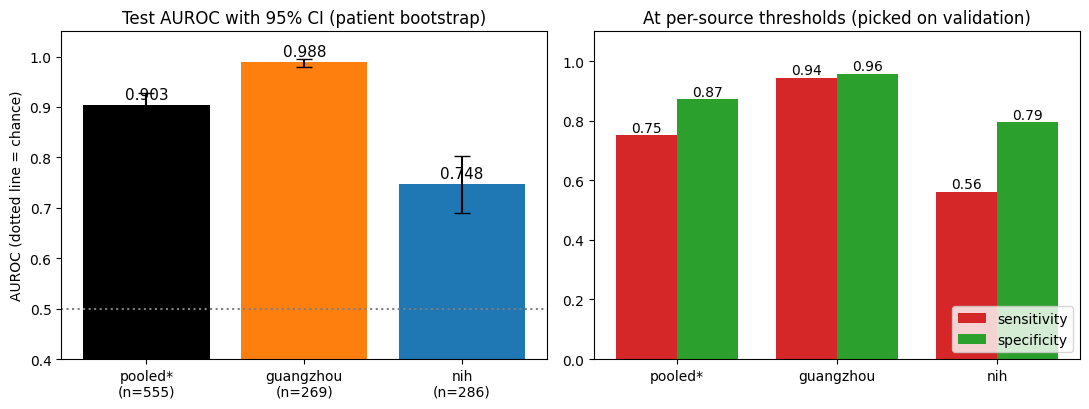

   source   n  auroc  auroc_lo  auroc_hi  sens  spec
      all 555  0.903     0.877     0.928 0.751 0.872
guangzhou 269  0.988     0.979     0.996 0.945 0.958
      nih 286  0.748     0.689     0.802 0.562 0.795
* pooled mixes the sources and is dominated by the easier one: quote the per-source numbers.


In [17]:
# ---- 1. HEADLINE NUMBERS: AUROC (95% CI), sensitivity and specificity per source ---------------
def _metrics(m):
    tn, fp, fn, tp = confusion_matrix(yt[m], pred[m], labels=[0, 1]).ravel()
    return dict(n=int(m.sum()), auroc=roc_auc_score(yt[m], pt[m]) if has_both(m) else np.nan, sens=tp / max(tp + fn, 1), spec=tn / max(tn + fp, 1))
rows = []
for name, m in [("all", ALL_MASK)] + [(s, src_mask(s)) for s in SRC]:
    src = results["overall"] if name == "all" else results["per_source"].get(name, {})
    lo, hi = src.get("auroc_ci") or [np.nan, np.nan]
    rows.append(dict(source=name, **_metrics(m), auroc_lo=lo, auroc_hi=hi))
H = pd.DataFrame(rows)
x = np.arange(len(H)); err = np.vstack([H.auroc - H.auroc_lo, H.auroc_hi - H.auroc]); has_ci = not np.isnan(err).any()
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
ax[0].bar(x, H.auroc, color=[COL.get(s, "gray") for s in H.source], yerr=err if has_ci else None, capsize=6)
for xi, v in zip(x, H.auroc): ax[0].text(xi, v + 0.012, f"{v:.3f}", ha="center", fontsize=11)
ax[0].axhline(0.5, color="gray", ls=":"); ax[0].set_ylim(0.4, 1.05); ax[0].set_xticks(x)
ax[0].set_xticklabels([f"{'pooled*' if s == 'all' else s}\n(n={n})" for s, n in zip(H.source, H.n)]); ax[0].set_ylabel("AUROC (dotted line = chance)")
ax[0].set_title("Test AUROC" + (" with 95% CI (patient bootstrap)" if has_ci else "  (run the bootstrap cell for CIs)"))
w = 0.38
ax[1].bar(x - w / 2, H.sens, w, color="tab:red", label="sensitivity"); ax[1].bar(x + w / 2, H.spec, w, color="tab:green", label="specificity")
for xi, a_, b_ in zip(x, H.sens, H.spec):
    ax[1].text(xi - w / 2, a_ + 0.012, f"{a_:.2f}", ha="center", fontsize=10); ax[1].text(xi + w / 2, b_ + 0.012, f"{b_:.2f}", ha="center", fontsize=10)
ax[1].set_ylim(0, 1.1); ax[1].set_xticks(x); ax[1].set_xticklabels(["pooled*" if s == "all" else s for s in H.source])
_mode = (results.get("thresholds") or {}).get("mode", "shared")
ax[1].set_title("At per-source thresholds (picked on validation)" if _mode == "per_source" else f"At the shared threshold ({t:.2f})"); ax[1].legend(loc="lower right")
fig.tight_layout(); savefig(fig, "1_headline"); plt.show()
print(H[["source", "n", "auroc", "auroc_lo", "auroc_hi", "sens", "spec"]].round(3).to_string(index=False))
print("* pooled mixes the sources and is dominated by the easier one: quote the per-source numbers.")

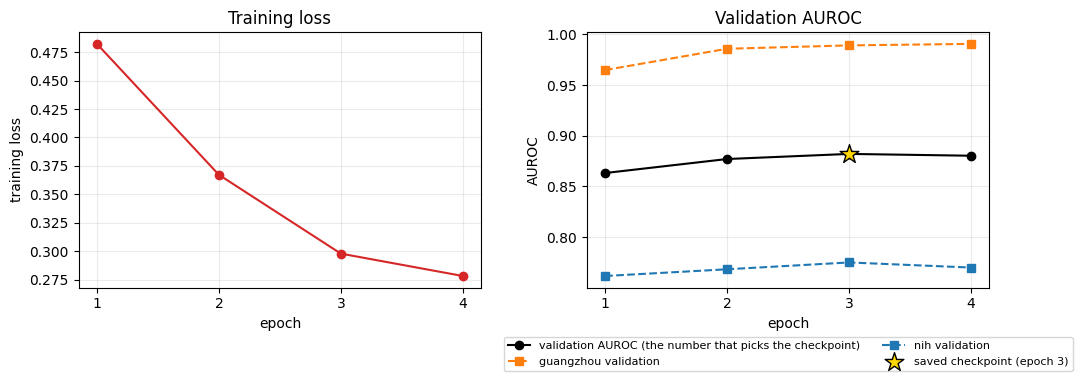

Reading it: loss still falling while validation AUROC is flat or dropping means overfitting; the star marks the epoch that was saved.


In [18]:
# ---- 2. TRAINING CURVES: train loss and validation AUROC per epoch ----------------------------
hist = list(globals().get("history", []))
if not hist and (RUN_DIR / "history.json").exists():
    hist = json.load(open(RUN_DIR / "history.json"))
if not hist:
    print("No training history for this run (a finished checkpoint was loaded instead of training). Set RETRAIN = True once to record one.")
else:
    ep = [h["epoch"] for h in hist]; va = [h["val_auroc"] for h in hist]; best = int(np.argmax(va))
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(ep, [h["train_loss"] for h in hist], "o-", color="tab:red"); ax[0].set_xlabel("epoch"); ax[0].set_ylabel("training loss"); ax[0].set_title("Training loss"); ax[0].grid(alpha=0.25)
    ax[1].plot(ep, va, "o-", color="k", label="validation AUROC (the number that picks the checkpoint)")
    per = [h.get("val_per_source") for h in hist]
    if all(per):
        for s in sorted({k for d in per for k in d}): ax[1].plot(ep, [d.get(s, np.nan) for d in per], "s--", color=COL.get(s, "gray"), label=f"{s} validation")
    ax[1].scatter([ep[best]], [va[best]], s=200, marker="*", color="gold", edgecolor="k", zorder=5, label=f"saved checkpoint (epoch {ep[best]})")
    ax[1].set_xlabel("epoch"); ax[1].set_ylabel("AUROC"); ax[1].set_title("Validation AUROC"); ax[1].grid(alpha=0.25)
    ax[1].legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=2)
    for a_ in ax: a_.set_xticks(ep)
    fig.tight_layout(); savefig(fig, "2_training_curves"); plt.show()
    print("Reading it: loss still falling while validation AUROC is flat or dropping means overfitting; the star marks the epoch that was saved.")

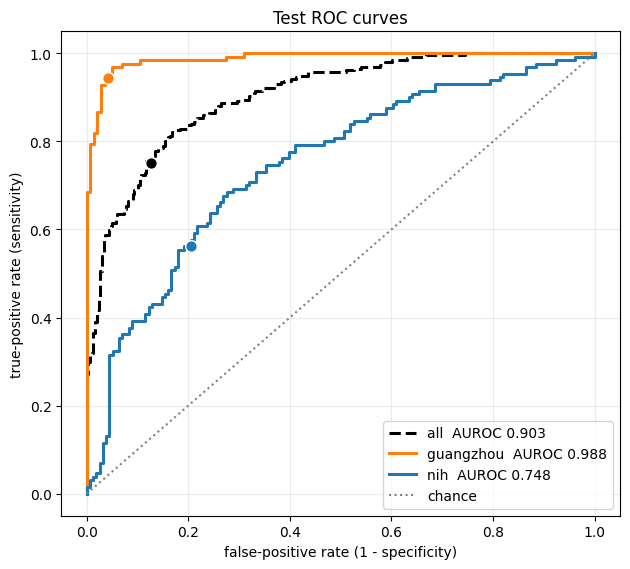

In [19]:
# ---- 3. ROC CURVES (dot = operating point at the chosen threshold) ---------------------------
fig, ax = plt.subplots(figsize=(6.4, 5.8))
for name, m in [("all", ALL_MASK)] + [(s, src_mask(s)) for s in SRC]:
    if not has_both(m): continue
    fpr_, tpr_, _ = roc_curve(yt[m], pt[m])
    ax.plot(fpr_, tpr_, lw=2.2, color=COL.get(name, "gray"), ls="--" if name == "all" else "-", label=f"{name}  AUROC {roc_auc_score(yt[m], pt[m]):.3f}")
    ax.scatter((pred[m][yt[m] == 0] == 1).mean(), (pred[m][yt[m] == 1] == 1).mean(), s=70, color=COL.get(name, "gray"), edgecolor="white", zorder=5)
ax.plot([0, 1], [0, 1], ":", color="gray", label="chance")
ax.set_xlabel("false-positive rate (1 - specificity)"); ax.set_ylabel("true-positive rate (sensitivity)"); ax.set_title("Test ROC curves")
ax.legend(loc="lower right"); ax.grid(alpha=0.25)
fig.tight_layout(); savefig(fig, "3_roc"); plt.show()

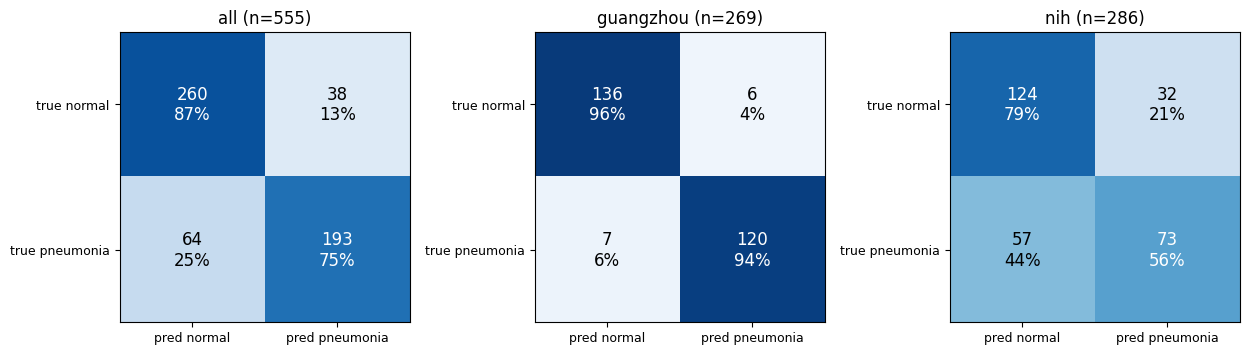

In [20]:
# ---- 4. CONFUSION MATRICES at the chosen threshold (count and share of each true class) ---------
groups = [("all", ALL_MASK)] + [(s, src_mask(s)) for s in SRC]
fig, axes = plt.subplots(1, len(groups), figsize=(4.2 * len(groups), 4), squeeze=False)
for ax, (name, m) in zip(axes[0], groups):
    cm = confusion_matrix(yt[m], pred[m], labels=[0, 1]); pct = cm / np.clip(cm.sum(axis=1, keepdims=True), 1, None)
    ax.imshow(pct, cmap="Blues", vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]}\n{pct[i, j]:.0%}", ha="center", va="center", fontsize=12, color="white" if pct[i, j] > 0.5 else "black")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["pred normal", "pred pneumonia"], fontsize=9)
    ax.set_yticks([0, 1]); ax.set_yticklabels(["true normal", "true pneumonia"], fontsize=9); ax.set_title(f"{name} (n={int(m.sum())})")
fig.tight_layout(); savefig(fig, "4_confusion"); plt.show()

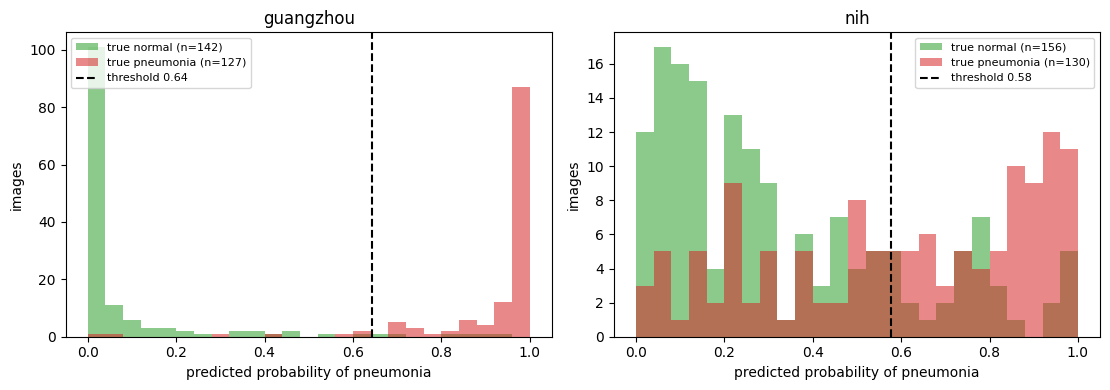

Reading it: two clean humps at opposite ends = confident separation; heavy overlap = the model is unsure. Very confident mistakes are worth looking at in section 8.


In [21]:
# ---- 5. SCORE DISTRIBUTIONS: how cleanly does the model separate the classes? ------------------
bins = np.linspace(0, 1, 26)
fig, axes = plt.subplots(1, len(SRC), figsize=(5.6 * len(SRC), 4), squeeze=False)
for ax, s in zip(axes[0], SRC):
    m = src_mask(s)
    for c, col in ((0, "tab:green"), (1, "tab:red")):
        sel = m & (yt == c); ax.hist(pt[sel], bins=bins, alpha=0.55, color=col, label=f"true {CLS[c]} (n={int(sel.sum())})")
    ax.axvline(tsrc(s), color="k", ls="--", label=f"threshold {tsrc(s):.2f}")
    ax.set_xlabel("predicted probability of pneumonia"); ax.set_ylabel("images"); ax.set_title(s); ax.legend(fontsize=8)
fig.tight_layout(); savefig(fig, "5_score_distributions"); plt.show()
print("Reading it: two clean humps at opposite ends = confident separation; heavy overlap = the model is unsure. Very confident mistakes are worth looking at in section 8.")

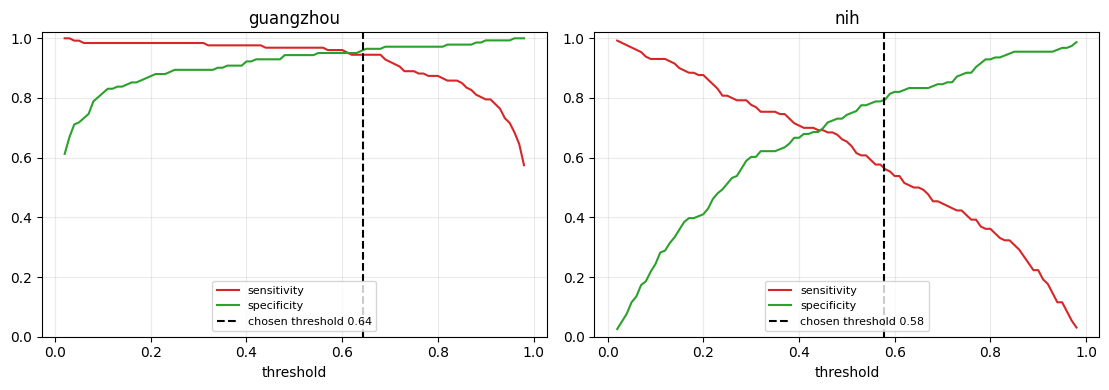

Reading it: the curves show what each threshold would give for that source. A shared threshold follows the easy source; per-source thresholds avoid that.


In [22]:
# ---- 6. THRESHOLD SWEEP: sensitivity and specificity as the threshold moves ------------------
ths = np.linspace(0.02, 0.98, 97)
fig, axes = plt.subplots(1, len(SRC), figsize=(5.6 * len(SRC), 4), squeeze=False)
for ax, s in zip(axes[0], SRC):
    m = src_mask(s); y, p = yt[m], pt[m]
    sens = [((p >= th) & (y == 1)).sum() / max((y == 1).sum(), 1) for th in ths]
    spec = [((p < th) & (y == 0)).sum() / max((y == 0).sum(), 1) for th in ths]
    ax.plot(ths, sens, color="tab:red", label="sensitivity"); ax.plot(ths, spec, color="tab:green", label="specificity")
    ax.axvline(tsrc(s), color="k", ls="--", label=f"chosen threshold {tsrc(s):.2f}")
    ax.set_xlabel("threshold"); ax.set_ylim(0, 1.02); ax.set_title(s); ax.grid(alpha=0.25); ax.legend(fontsize=8, loc="lower center")
fig.tight_layout(); savefig(fig, "6_threshold_sweep"); plt.show()
print("Reading it: the curves show what each threshold would give for that source. A shared threshold follows the easy source; per-source thresholds avoid that.")

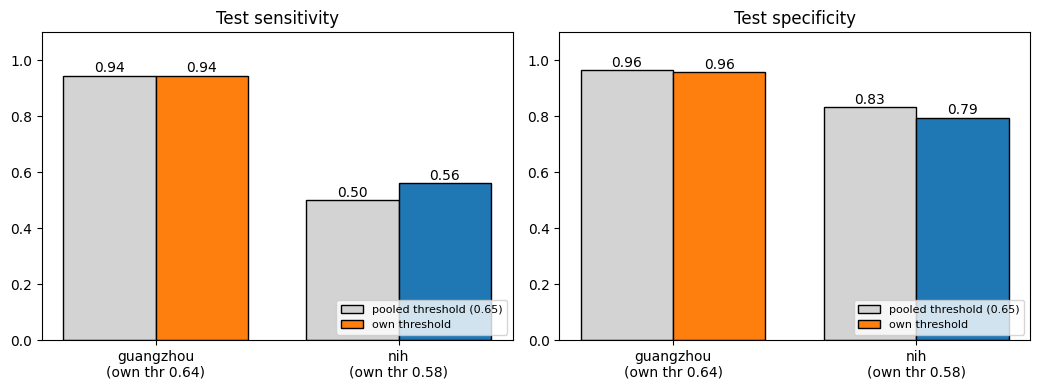

   source  shared_thr  sens_shared  spec_shared  own_thr  sens_own  spec_own
guangzhou       0.652        0.945        0.965    0.644     0.945     0.958
      nih       0.652        0.500        0.833    0.577     0.562     0.795
Reading it: the threshold is only a choice of operating point; AUROC does not change. A single threshold fitted on pooled validation data follows the easy source.
A source-specific threshold assumes you know where an image came from (true within one hospital). It is chosen on validation images only, so these test numbers stay honest.


In [23]:
# ---- 6b. PER-SOURCE THRESHOLDS: what changes if each source gets its own threshold (picked on that source's VALIDATION images)? ----
_need = [v for v in ("pv", "yv", "val") if v not in globals()]
if _need:
    print("Needs the evaluation cell (missing:", _need, ")")
else:
    rows = []
    for s in SRC:
        mv = (val.source == s).values
        if mv.sum() == 0 or len(np.unique(yv[mv])) < 2: continue
        fpr_, tpr_, thr_ = roc_curve(yv[mv], pv[mv]); ts = float(thr_[np.argmax(tpr_ - fpr_)])          # Youden's J on this source's validation images
        m = src_mask(s); y = yt[m]
        tn0, fp0, fn0, tp0 = confusion_matrix(y, (pt[m] >= t).astype(int), labels=[0, 1]).ravel()
        tn1, fp1, fn1, tp1 = confusion_matrix(y, (pt[m] >= ts).astype(int), labels=[0, 1]).ravel()
        rows.append(dict(source=s, shared_thr=round(t, 3), sens_shared=tp0 / max(tp0 + fn0, 1), spec_shared=tn0 / max(tn0 + fp0, 1),
                         own_thr=round(ts, 3), sens_own=tp1 / max(tp1 + fn1, 1), spec_own=tn1 / max(tn1 + fp1, 1)))
    if not rows:
        print("No source has both classes in the validation set.")
    else:
        T = pd.DataFrame(rows); x = np.arange(len(T)); w = 0.38
        fig, axes = plt.subplots(1, 2, figsize=(10.5, 4))
        for ax, (lab, a, b) in zip(axes, [("sensitivity", "sens_shared", "sens_own"), ("specificity", "spec_shared", "spec_own")]):
            ax.bar(x - w / 2, T[a], w, color="lightgray", edgecolor="k", label=f"pooled threshold ({t:.2f})")
            ax.bar(x + w / 2, T[b], w, color=[COL.get(s, "gray") for s in T.source], edgecolor="k", label="own threshold")
            for xi, v1, v2 in zip(x, T[a], T[b]):
                ax.text(xi - w / 2, v1 + 0.012, f"{v1:.2f}", ha="center", fontsize=10); ax.text(xi + w / 2, v2 + 0.012, f"{v2:.2f}", ha="center", fontsize=10)
            ax.set_ylim(0, 1.1); ax.set_xticks(x); ax.set_xticklabels([f"{s}\n(own thr {o:.2f})" for s, o in zip(T.source, T.own_thr)]); ax.set_title(f"Test {lab}"); ax.legend(loc="lower right", fontsize=8)
        fig.tight_layout(); savefig(fig, "6b_per_source_thresholds"); plt.show()
        print(T.round(3).to_string(index=False))
        print("Reading it: the threshold is only a choice of operating point; AUROC does not change. A single threshold fitted on pooled validation data follows the easy source.")
        print("A source-specific threshold assumes you know where an image came from (true within one hospital). It is chosen on validation images only, so these test numbers stay honest.")

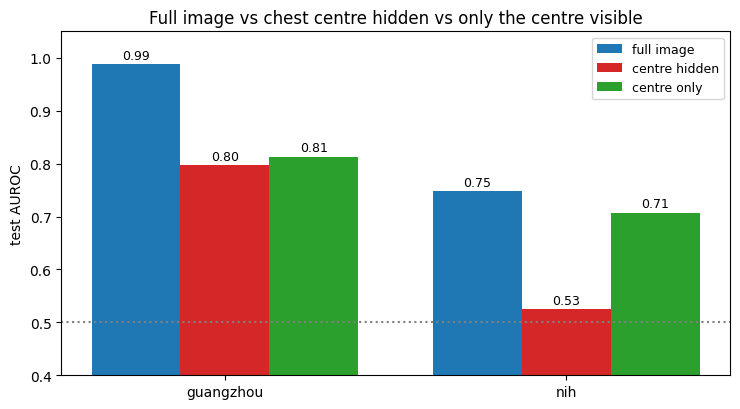

Reading it: a source whose AUROC stays far above 0.5 with the centre hidden is being read through borders, markers or image style.
The model never trained on masked images, so this is a hint, not proof.


In [24]:
# ---- 7. CENTRE-MASKING DIAGNOSTIC: does the model still "see" pneumonia when the chest centre is hidden? ----
ps = results["per_source"]
if not any("masked" in ps.get(s, {}) for s in SRC):
    print("Run the shortcut-diagnostic cell first: this chart reads its results.")
else:
    modes = [("full image", lambda d: d.get("auroc")), ("centre hidden", lambda d: (d.get("masked") or {}).get("hide_center")),
             ("centre only", lambda d: (d.get("masked") or {}).get("center_only"))]
    fig, ax = plt.subplots(figsize=(7.5, 4.2)); w = 0.26; x = np.arange(len(SRC))
    for j, (lab, fn) in enumerate(modes):
        vals = np.array([np.nan if fn(ps.get(s, {})) is None else fn(ps.get(s, {})) for s in SRC], dtype=float)
        ax.bar(x + (j - 1) * w, vals, w, label=lab, color=["tab:blue", "tab:red", "tab:green"][j])
        for xi, v in zip(x + (j - 1) * w, vals):
            if not np.isnan(v): ax.text(xi, v + 0.01, f"{v:.2f}", ha="center", fontsize=9)
    ax.axhline(0.5, color="gray", ls=":"); ax.set_ylim(0.4, 1.05); ax.set_xticks(x); ax.set_xticklabels(SRC); ax.set_ylabel("test AUROC")
    ax.set_title("Full image vs chest centre hidden vs only the centre visible"); ax.legend(loc="upper right", fontsize=9)
    fig.tight_layout(); savefig(fig, "7_masking"); plt.show()
    print("Reading it: a source whose AUROC stays far above 0.5 with the centre hidden is being read through borders, markers or image style.")
    print("The model never trained on masked images, so this is a hint, not proof.")

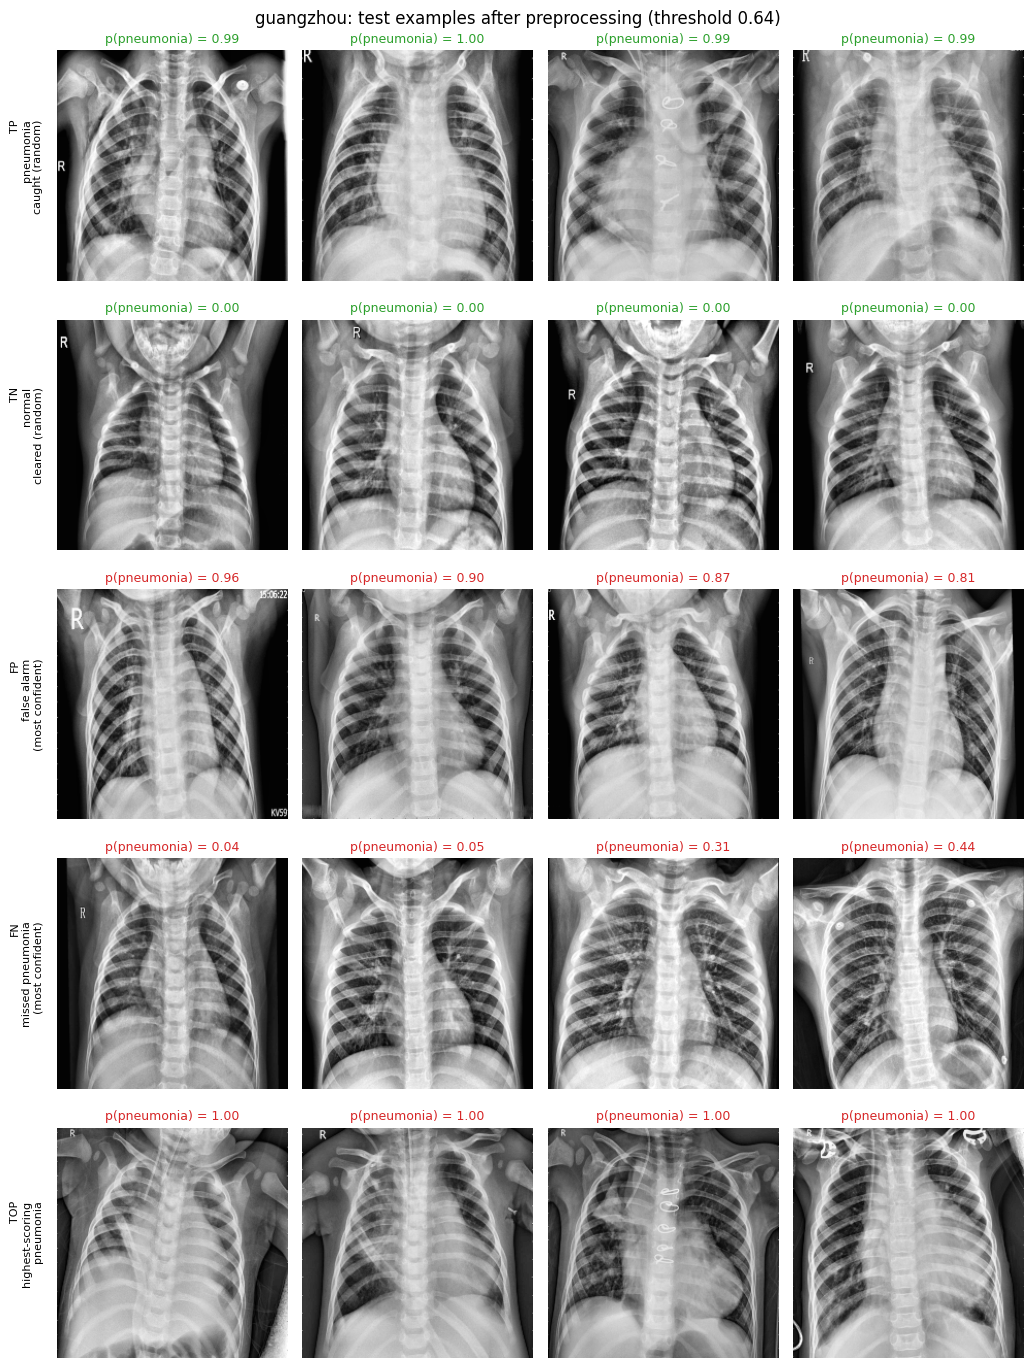

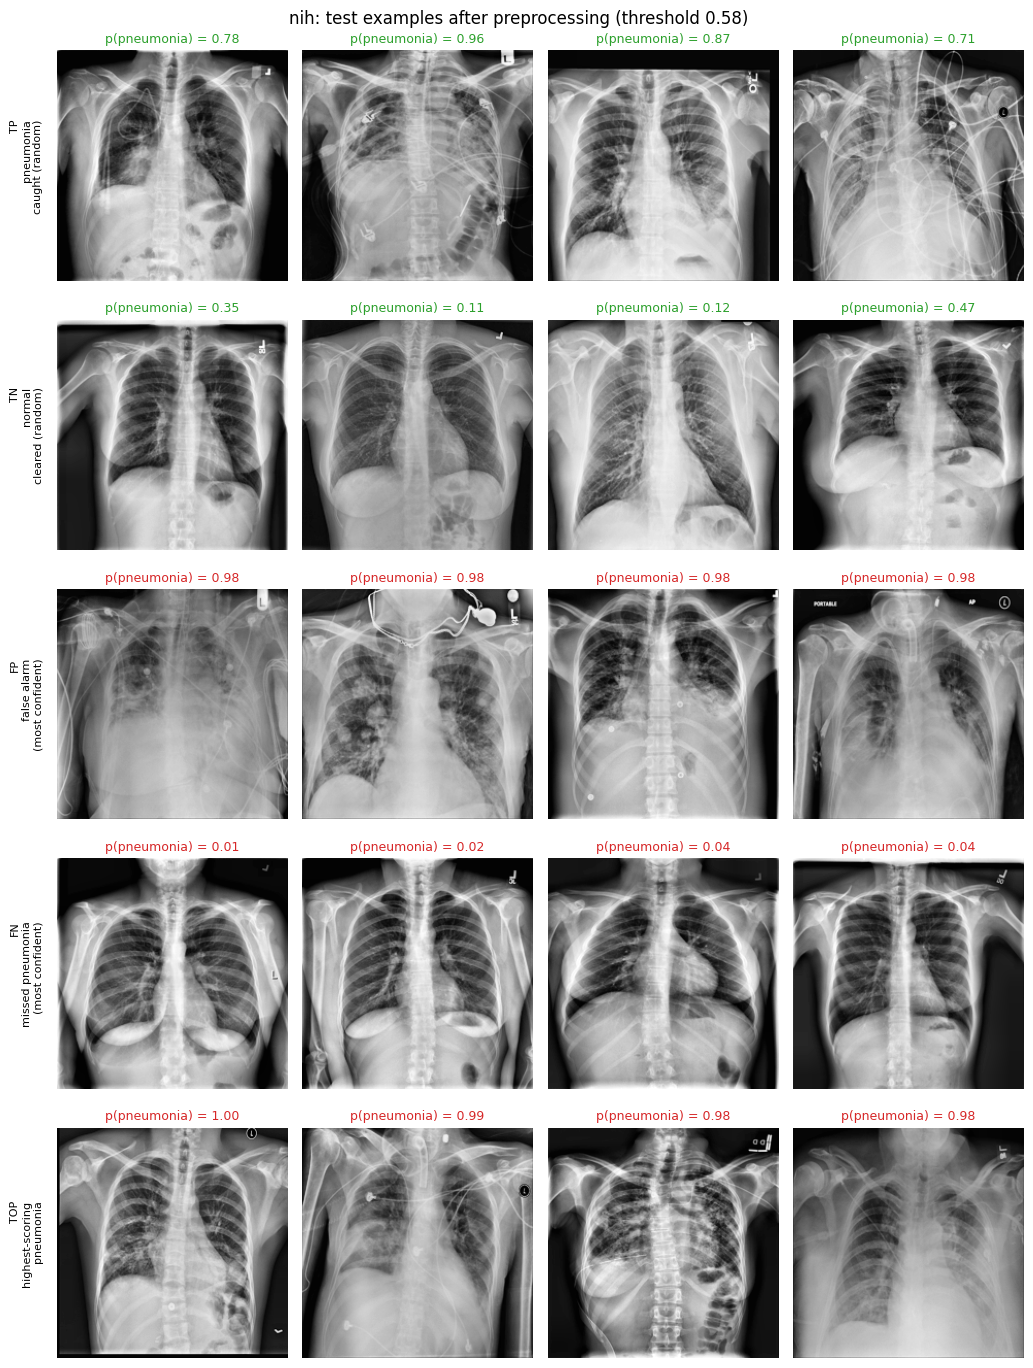

In [25]:
# ---- 8. EXAMPLE PREDICTIONS: what the network sees (after preprocessing) and what it decided -------
KINDS = [("TP", "pneumonia\ncaught (random)"), ("TN", "normal\ncleared (random)"),
         ("FP", "false alarm\n(most confident)"), ("FN", "missed pneumonia\n(most confident)"),
         ("TOP", "highest-scoring\npneumonia")]
for s in SRC:
    m = src_mask(s)
    fig, axes = plt.subplots(len(KINDS), N_EXAMPLES, figsize=(2.6 * N_EXAMPLES, 2.8 * len(KINDS)), squeeze=False)
    for r, (kind, desc) in enumerate(KINDS):
        ids = pick(m, kind)
        for c in range(N_EXAMPLES):
            ax = axes[r, c]; ax.axis("off")
            if c < len(ids):
                i = ids[c]; ax.imshow(load_and_preprocess(test.path.iloc[i])[..., 0], cmap="gray", vmin=0, vmax=255)
                ax.set_title(f"p(pneumonia) = {pt[i]:.2f}", fontsize=9, color="tab:green" if kind in ("TP", "TN") else "tab:red")
        axes[r, 0].text(-0.06, 0.5, f"{kind}\n{desc}", transform=axes[r, 0].transAxes, rotation=90, va="center", ha="right", fontsize=8)
    fig.suptitle(f"{s}: test examples after preprocessing (threshold {tsrc(s):.2f})", fontsize=12)
    fig.tight_layout(); savefig(fig, f"8_examples_{s}"); plt.show()

C:\Users\admin\AppData\Local\Temp\ipykernel_28856\2768771812.py:21: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\torch\csrc\autograd\generated\python_variable_methods.cpp:836.)
  return cam / (cam.max() + 1e-8), float(torch.sigmoid(logit))


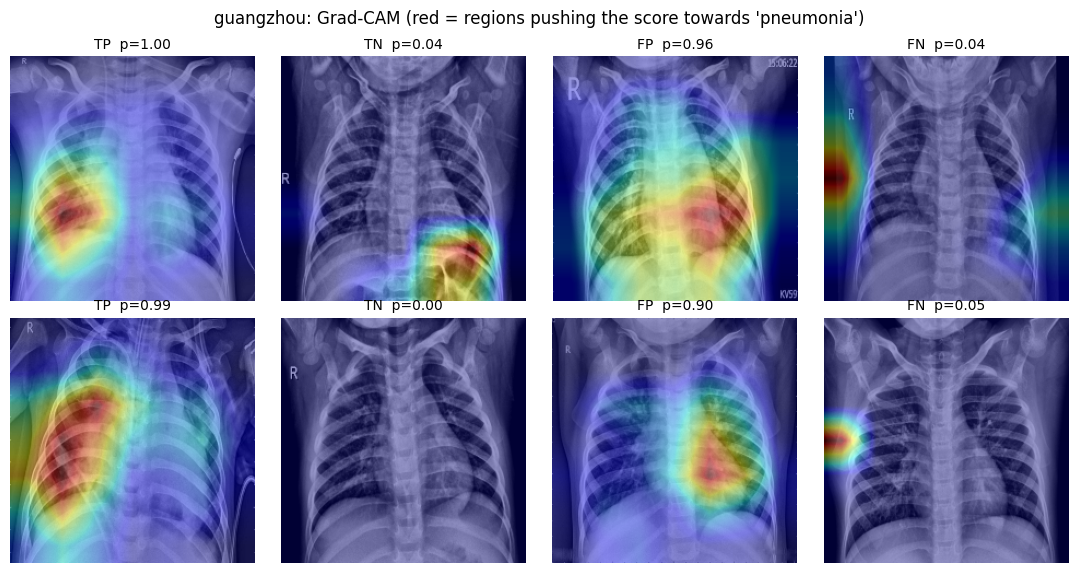

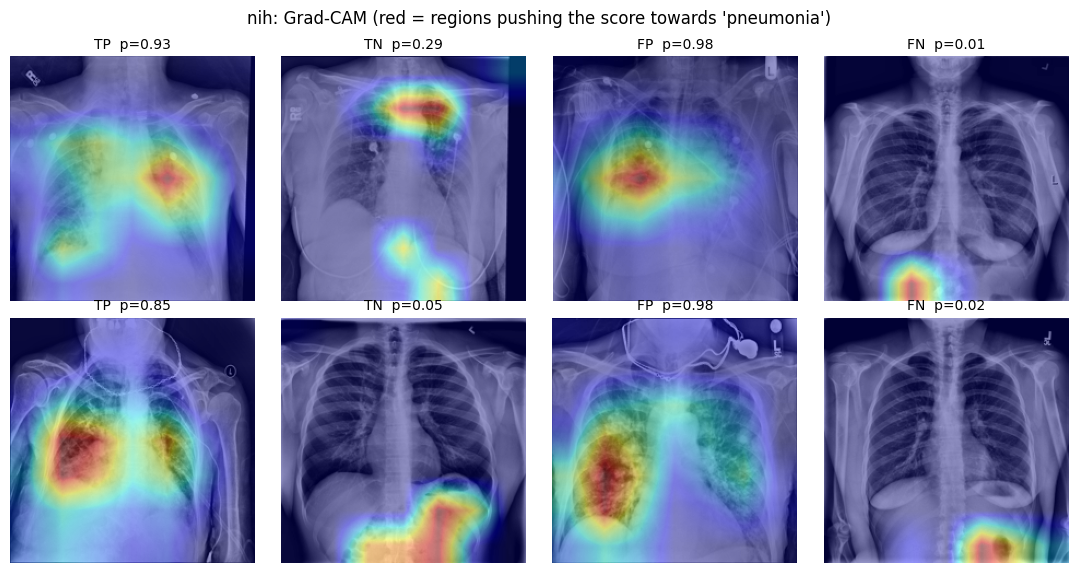

Reading it: heat on borders, corners, text markers or outside the lungs is the shortcut we worried about; heat on the lung fields is reassuring.
Grad-CAM is coarse (7x7, upsampled), so judge patterns across many images, not single ones.


In [26]:
# ---- 9. GRAD-CAM: where does the model look? (needs the trained model in memory; CPU is fine) ----------------
N_CAM = 2                                        # examples per category and source
try:
    import torch.nn.functional as F
    cam_layer = model.features[-1]               # last convolutional block of EfficientNet-B0 (7x7 map)

    def gradcam(path):
        x = eval_tf(load_and_preprocess(path)).unsqueeze(0).to(device)
        store = {}
        handle = cam_layer.register_forward_hook(lambda mod, inp, out: store.__setitem__("a", out))
        try:
            model.eval()
            logit = model(x).squeeze()
            grad = torch.autograd.grad(logit, store["a"])[0]
        finally:
            handle.remove()
        weights = grad.mean(dim=(2, 3), keepdim=True)
        cam = torch.relu((weights * store["a"]).sum(dim=1, keepdim=True))
        cam = F.interpolate(cam, size=(224, 224), mode="bilinear", align_corners=False)[0, 0].detach().cpu().numpy()
        cam = cam - cam.min()
        return cam / (cam.max() + 1e-8), float(torch.sigmoid(logit))

    for s in SRC:
        m = src_mask(s)
        fig, axes = plt.subplots(N_CAM, 4, figsize=(11, 2.9 * N_CAM), squeeze=False)
        for c, kind in enumerate(("TP", "TN", "FP", "FN")):
            ids = pick(m, kind, k=N_CAM)
            for r in range(N_CAM):
                ax = axes[r, c]; ax.axis("off")
                if r < len(ids):
                    path = test.path.iloc[ids[r]]; cam, p_ = gradcam(path)
                    ax.imshow(load_and_preprocess(path)[..., 0], cmap="gray", vmin=0, vmax=255); ax.imshow(cam, cmap="jet", alpha=0.4)
                    ax.set_title(f"{kind}  p={p_:.2f}", fontsize=10)
        fig.suptitle(f"{s}: Grad-CAM (red = regions pushing the score towards 'pneumonia')", fontsize=12)
        fig.tight_layout(); savefig(fig, f"9_gradcam_{s}"); plt.show()
    print("Reading it: heat on borders, corners, text markers or outside the lungs is the shortcut we worried about; heat on the lung fields is reassuring.")
    print("Grad-CAM is coarse (7x7, upsampled), so judge patterns across many images, not single ones.")
except Exception as e:
    print("Grad-CAM skipped:", type(e).__name__, "-", e)

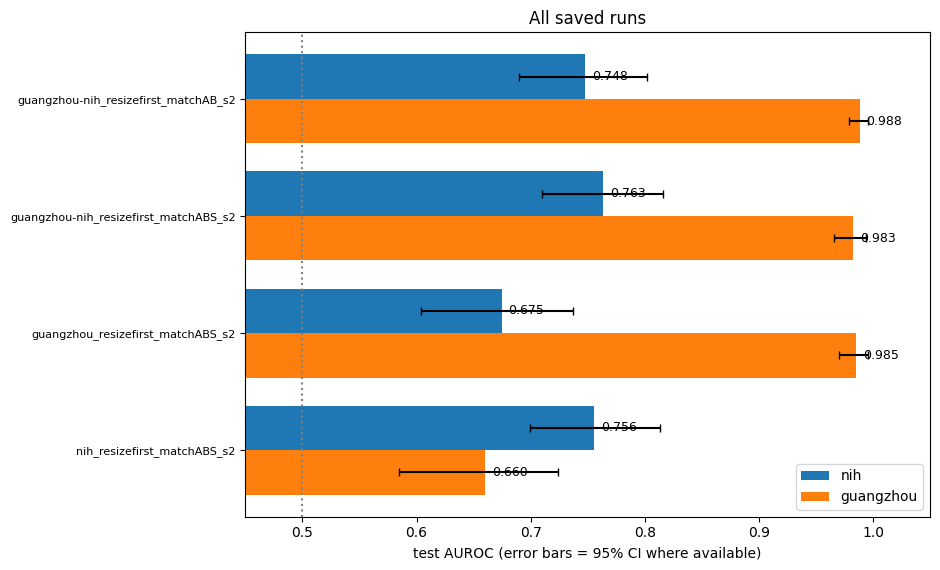

In [27]:
# ---- 10. ALL SAVED RUNS SIDE BY SIDE (NIH and Guangzhou AUROC, 95% CI where available) ---------
recs = []
for f in sorted(Path("runs").glob("*/results.json")):
    try: r = json.load(open(f))
    except Exception: continue
    for s in ("nih", "guangzhou"):
        d = r.get("per_source", {}).get(s, {})
        if "auroc" in d:
            lo, hi = d.get("auroc_ci") or [np.nan, np.nan]
            recs.append(dict(run=r.get("run_name", f.parent.name), source=s, auroc=d["auroc"], lo=lo, hi=hi))
if not recs:
    print("No saved runs yet (they appear after the evaluation cell has run).")
else:
    R = pd.DataFrame(recs); runs_ = list(dict.fromkeys(R.run))
    fig, ax = plt.subplots(figsize=(9.5, 0.9 * len(runs_) + 2.2)); h = 0.38
    for j, s in enumerate(("nih", "guangzhou")):
        d = R[R.source == s].set_index("run").reindex(runs_)
        y = np.arange(len(runs_)) + (j - 0.5) * h
        err = np.vstack([d.auroc - d.lo, d.hi - d.auroc]); ok = not np.isnan(err).any()
        ax.barh(y, d.auroc, h, color=COL[s], label=s, xerr=err if ok else None, capsize=3)
        for yi, v in zip(y, d.auroc):
            if not np.isnan(v): ax.text(v + 0.006, yi, f"{v:.3f}", va="center", fontsize=9)
    ax.axvline(0.5, color="gray", ls=":"); ax.set_xlim(0.45, 1.05); ax.set_yticks(np.arange(len(runs_))); ax.set_yticklabels(runs_, fontsize=8); ax.invert_yaxis()
    ax.set_xlabel("test AUROC (error bars = 95% CI where available)"); ax.set_title("All saved runs"); ax.legend(loc="lower right")
    fig.tight_layout(); savefig(fig, "10_all_runs"); plt.show()

In [28]:
# ---- 11. SELF-CHECK: rough rules of thumb for this run (heuristics, not proofs) ---------------
checks = []
def add(name, ok, detail): checks.append(dict(check=name, result="PASS" if ok is True else "WARN" if ok is False else "n/a", detail=detail))
ps = results["per_source"]; nih, gz = ps.get("nih", {}), ps.get("guangzhou", {})
lo = (nih.get("auroc_ci") or [np.nan])[0]
if "auroc" in nih and not np.isnan(lo): add("NIH AUROC clearly above chance (95% CI lower bound > 0.5)", bool(lo > 0.5), f"NIH AUROC {nih['auroc']:.3f}, CI lower bound {lo:.3f}")
else: add("NIH AUROC clearly above chance (95% CI lower bound > 0.5)", None, "needs the NIH source and the bootstrap cell")
if "auroc" in nih and "auroc" in gz:
    gap = gz["auroc"] - nih["auroc"]; add("Guangzhou vs NIH AUROC gap below 0.10 (a big gap hints at source shortcuts)", bool(abs(gap) < 0.10), f"gap {gap:+.3f}")
else: add("Guangzhou vs NIH AUROC gap below 0.10", None, "needs both sources")
add("Predicted-positive rate within 0.10 of the true rate", bool(abs(pred.mean() - yt.mean()) < 0.10), f"predicted {pred.mean():.2f} vs true {yt.mean():.2f}")
mh = (nih.get("masked") or {}).get("hide_center")
add("NIH AUROC with the chest centre hidden stays near chance (<= 0.60)", None if mh is None else bool(mh <= 0.60), "run the shortcut-diagnostic cell" if mh is None else f"{mh:.3f}")
sb = results.get("source_only_baseline_auroc")
add("Source-only baseline near 0.5 (0.45 to 0.55)", None if sb is None else bool(0.45 <= sb <= 0.55), "run the bootstrap cell" if sb is None else f"{sb:.3f}")
hist_ = list(globals().get("history", [])) or (json.load(open(RUN_DIR / "history.json")) if (RUN_DIR / "history.json").exists() else [])
if len(hist_) >= 2:
    va_ = [h["val_auroc"] for h in hist_]
    add("Validation AUROC stayed within 0.02 of its best (otherwise it overfit; the best epoch is what gets saved)", bool(max(va_) - va_[-1] < 0.02), f"best {max(va_):.3f} at epoch {int(np.argmax(va_)) + 1}, last {va_[-1]:.3f}")
else: add("Overfitting check", None, "no training history")
pd.set_option("display.max_colwidth", 110); pd.set_option("display.width", 220)
print(pd.DataFrame(checks).to_string(index=False))
print("\nPASS / WARN are rough rules of thumb that point you at things worth a look; they do not prove or disprove anything.")

                                                                                                    check result                                detail
                                                NIH AUROC clearly above chance (95% CI lower bound > 0.5)   PASS NIH AUROC 0.748, CI lower bound 0.689
                              Guangzhou vs NIH AUROC gap below 0.10 (a big gap hints at source shortcuts)   WARN                            gap +0.240
                                                     Predicted-positive rate within 0.10 of the true rate   PASS           predicted 0.42 vs true 0.46
                                       NIH AUROC with the chest centre hidden stays near chance (<= 0.60)   PASS                                 0.526
                                                             Source-only baseline near 0.5 (0.45 to 0.55)   PASS                                 0.491
Validation AUROC stayed within 0.02 of its best (otherwise it overfit; the best epoch is what 

In [29]:
# ---- 12. SEED NOISE: mean and spread of test AUROC over runs that differ only in SEED -------------------
groups = {}
for f in sorted(Path("runs").glob("*/results.json")):
    try: r = json.load(open(f))
    except Exception: continue
    cfg = dict(r.get("config", {})); seed = cfg.pop("SEED", None)
    if seed is None: continue
    groups.setdefault(json.dumps(cfg, sort_keys=True, default=str), []).append((seed, r))
rows = []
for key, lst in groups.items():
    if len(lst) < 2: continue
    cfg = json.loads(key)
    for s in ("nih", "guangzhou"):
        v = [r["per_source"][s]["auroc"] for _, r in lst if "auroc" in r.get("per_source", {}).get(s, {})]
        if len(v) >= 2:
            rows.append(dict(config=f"{'+'.join(cfg.get('TRAIN_SOURCES', []))} | clahe_first={cfg.get('CLAHE_FIRST')} | norm={cfg.get('INTENSITY_NORM')} | match={cfg.get('MATCH_GZ_ASPECT')}/{cfg.get('MATCH_GZ_BORDER')}",
                             source=s, runs=len(v), mean=np.mean(v), sd=np.std(v, ddof=1), min=min(v), max=max(v)))
if rows:
    print(pd.DataFrame(rows).round(3).to_string(index=False))
    print("\nReading it: the sd is the run-to-run noise of this setup (each seed changes the split AND the initialisation). Differences between configs smaller than about 2 sd are not trustworthy.")
else:
    print("Needs at least two finished runs of the SAME config that differ only in SEED (set SEED in the CONFIG cell; each seed also changes the train/val/test split).")

Needs at least two finished runs of the SAME config that differ only in SEED (set SEED in the CONFIG cell; each seed also changes the train/val/test split).


images compared: {'train': 2865, 'val': 562, 'test': 555}
test -> train nearest-neighbour correlation: median 0.892, 95th percentile 0.936, maximum 0.954
1 near-duplicate pairs across splits (saved to runs\guangzhou-nih_resizefirst_matchAB_s2\duplicates.csv):
split_a  split_b  source   
val      train    guangzhou    1


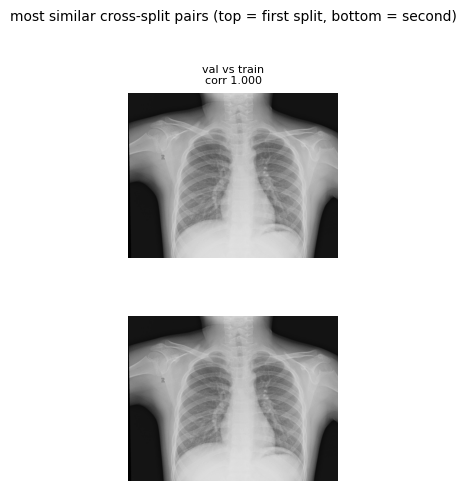

If these are true duplicates: drop them from TRAIN (keep test fixed) and re-run. Look at the pairs first: very similar chests are not always the same picture.


In [30]:
# ---- 13. AUDIT: near-duplicate images across train / val / test ------------------------------------------
# The split keeps each patient on one side, but Guangzhou patient ids are guessed from file names. Comparing small normalised thumbnails catches the
# same picture appearing twice (re-saved copies, near-identical frames). It cannot catch the same patient photographed twice: that relies on the ids.
CORR_MIN = 0.98                                    # correlation of 64x64 thumbnails at or above which two images count as near-duplicates
def thumb(path):
    g = cv2.imread(str(path), cv2.IMREAD_REDUCED_GRAYSCALE_4)
    if g is None: return None
    v = cv2.resize(g, (64, 64), interpolation=cv2.INTER_AREA).astype(np.float32).ravel(); v -= v.mean()
    return v / (np.linalg.norm(v) + 1e-8)
def vectors(d):
    vs = [thumb(p) for p in d.path]; ok = np.array([v is not None for v in vs], dtype=bool)
    return d[ok].reset_index(drop=True), (np.stack([v for v in vs if v is not None]) if ok.any() else np.zeros((0, 4096), np.float32))
V = {n: vectors(d) for n, d in (("train", train), ("val", val), ("test", test))}
pairs, nn_corr = [], None
for a_, b_ in (("test", "train"), ("test", "val"), ("val", "train")):
    (A, VA), (B, VB) = V[a_], V[b_]
    if len(A) == 0 or len(B) == 0: continue
    Cm = VA @ VB.T                                  # all pairwise correlations in one matrix product
    if (a_, b_) == ("test", "train"): nn_corr = Cm.max(axis=1)
    for i, j in zip(*np.where(Cm >= CORR_MIN)):
        pairs.append(dict(split_a=a_, split_b=b_, source=A.source[i], corr=float(Cm[i, j]), same_patient=bool(A.patient[i] == B.patient[j]), path_a=A.path[i], path_b=B.path[j]))
D = pd.DataFrame(pairs).sort_values("corr", ascending=False).reset_index(drop=True) if pairs else pd.DataFrame(pairs)
print("images compared:", {n: len(v[0]) for n, v in V.items()})
if nn_corr is not None and len(nn_corr):
    print(f"test -> train nearest-neighbour correlation: median {np.median(nn_corr):.3f}, 95th percentile {np.percentile(nn_corr, 95):.3f}, maximum {nn_corr.max():.3f}")
    if np.median(nn_corr) >= CORR_MIN: print("!!! even a typical image has a near-identical partner: the images are too alike for this audit to separate duplicates (raise CORR_MIN or inspect by eye).")
if D.empty:
    print(f"No near-duplicate pairs (correlation >= {CORR_MIN}) across splits.")
else:
    RUN_DIR.mkdir(parents=True, exist_ok=True); D.to_csv(RUN_DIR / "duplicates.csv", index=False)
    print(f"{len(D)} near-duplicate pairs across splits (saved to {RUN_DIR / 'duplicates.csv'}):")
    print(D.groupby(["split_a", "split_b", "source"]).size().rename("pairs").to_string())
    if D.same_patient.any(): print("!!! some pairs share a patient id ACROSS splits: that would be a bug in the split.")
    k = min(6, len(D)); fig, axes = plt.subplots(2, k, figsize=(2.4 * k, 5.4), squeeze=False)
    for c in range(k):
        r_ = D.iloc[c]
        for rr, key in enumerate(("path_a", "path_b")):
            axes[rr, c].imshow(cv2.imread(str(r_[key]), cv2.IMREAD_GRAYSCALE), cmap="gray"); axes[rr, c].axis("off")
        axes[0, c].set_title(f"{r_.split_a} vs {r_.split_b}\ncorr {r_['corr']:.3f}", fontsize=8)
    fig.suptitle("most similar cross-split pairs (top = first split, bottom = second)", fontsize=10); fig.tight_layout(); savefig(fig, "13_duplicates"); plt.show()
    print("If these are true duplicates: drop them from TRAIN (keep test fixed) and re-run. Look at the pairs first: very similar chests are not always the same picture.")